# **Analyse de la Fiabilité d’un Parc de Serveurs de Calcul**

# Acquisition et Visualisation des Données

## Résultats graphiques

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min

# ─── Paramètres ──────────────────────────────────────────────────────────────
np.random.seed(42)          # reproductibilité
N        = 1000             # nombre de serveurs
beta     = 2.5              # paramètre de forme (β)
eta      = 5.0              # paramètre d'échelle (η), en milliers d'heures
n_bins   = 40               # nombre de classes pour l'histogramme

# ─── 1. Génération de l'échantillon Weibull ──────────────────────────────────
# scipy utilise la convention scale = eta, c = beta
durees = weibull_min.rvs(c=beta, scale=eta, size=N)

print(f"Moyenne empirique  : {durees.mean():.3f} milliers d'heures")
print(f"Écart-type empirique: {durees.std():.3f} milliers d'heures")
print(f"Min / Max          : {durees.min():.3f} / {durees.max():.3f}")

# ─── 2. Grille de temps pour les courbes ─────────────────────────────────────
t = np.linspace(0.001, durees.max() * 1.05, 500)

# ─── 3. Fiabilité empirique R̂(t) ─────────────────────────────────────────────
R_hat = np.array([(durees > ti).sum() / N for ti in t])

# ─── 4. Densité empirique f̂(t) et taux de défaillance λ̂(t) ──────────────────
counts, edges = np.histogram(durees, bins=n_bins, density=True)
mids          = 0.5 * (edges[:-1] + edges[1:])
dt            = edges[1] - edges[0]

# Interpolation pour avoir f̂ sur la même grille que t
f_hat     = np.interp(t, mids, counts, left=0, right=0)
lambda_hat = np.where(R_hat > 0.01, f_hat / R_hat, np.nan)

# ─── 5. Courbes théoriques Weibull ───────────────────────────────────────────
R_theo      = np.exp(-(t / eta)**beta)
f_theo      = (beta / eta) * (t / eta)**(beta - 1) * np.exp(-(t / eta)**beta)
lambda_theo = (beta / eta) * (t / eta)**(beta - 1)   # = β/η · (t/η)^(β-1)

# ─── 6. Figures ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(
    f"Analyse de fiabilité — Weibull(β={beta}, η={eta} milliers d'heures)\n"
    f"Échantillon de {N} serveurs",
    fontsize=13, fontweight='bold'
)

# ── Graphique 1 : Histogramme des durées de vie ──────────────────────────────
ax = axes[0]
ax.hist(durees, bins=n_bins, density=True, color='steelblue',
        edgecolor='white', alpha=0.75, label='Densité empirique')
ax.plot(t, f_theo, 'r-', lw=2, label='Densité théorique f(t)')
ax.set_xlabel("Durée de vie (milliers d'heures)", fontsize=11)
ax.set_ylabel("Densité de probabilité", fontsize=11)
ax.set_title("Histogramme des durées de vie", fontsize=12)
ax.legend()
ax.grid(alpha=0.3)

# ── Graphique 2 : Courbe de fiabilité R(t) ───────────────────────────────────
ax = axes[1]
ax.plot(t, R_hat,  'b-',  lw=1.5, label=r'$\hat{R}(t)$ empirique')
ax.plot(t, R_theo, 'r--', lw=2,   label=r'$R(t)$ théorique')
ax.axhline(0.5, color='gray', lw=1, linestyle=':', label='R(t) = 0.5')
ax.axhline(np.exp(-1), color='orange', lw=1, linestyle=':', label='R(η) ≈ 0.368')
ax.set_xlabel("Temps t (milliers d'heures)", fontsize=11)
ax.set_ylabel("Fiabilité R(t)", fontsize=11)
ax.set_title("Courbe de fiabilité (survie)", fontsize=12)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

# ── Graphique 3 : Taux de défaillance λ(t) ───────────────────────────────────
ax = axes[2]
ax.plot(t, lambda_hat,  'b-',  lw=1.5, label=r'$\hat{\lambda}(t)$ empirique')
ax.plot(t, lambda_theo, 'r--', lw=2,   label=r'$\lambda(t)$ théorique')
ax.set_xlabel("Temps t (milliers d'heures)", fontsize=11)
ax.set_ylabel("Taux de défaillance λ(t)", fontsize=11)
ax.set_title("Taux de défaillance (taux de hasard)", fontsize=12)
ax.set_ylim(0, lambda_theo[-1] * 1.2)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fiabilite_weibull.png", dpi=150, bbox_inches='tight')
plt.show()
print("Figure sauvegardée : fiabilite_weibull.png")

#**Analyse de sensibilité : illustration visuelle des différents régimes de β**

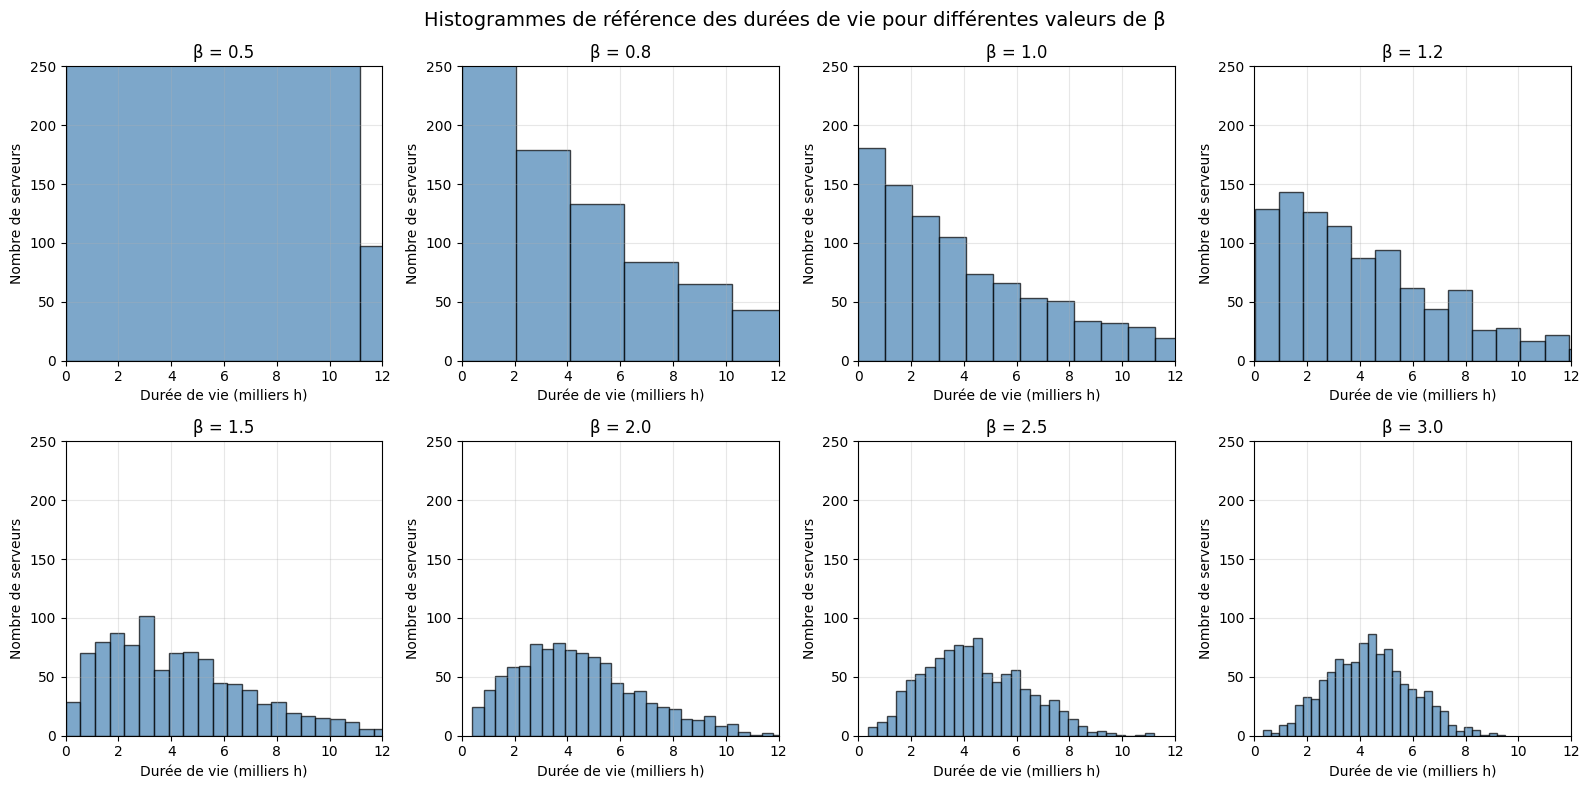

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Paramètres
np.random.seed(42)
n = 1000
eta = 5

beta_values = [0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Histogrammes de référence des durées de vie pour différentes valeurs de β", fontsize=14)

for i, beta in enumerate(beta_values):
    T = np.random.weibull(beta, n) * eta
    ax = axes[i // 4, i % 4]
    ax.hist(T, bins=30, density=False, alpha=0.7, color='steelblue', edgecolor='black')
    ax.set_title(f'β = {beta}')
    ax.set_xlabel('Durée de vie (milliers h)')
    ax.set_ylabel('Nombre de serveurs')
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 250)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('grille_histogrammes_beta.png', dpi=150, bbox_inches='tight')
plt.show()

# Régression linéaire — Estimation de β et η

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress, weibull_min

# ─── Paramètres de simulation ────────────────────────────────────────────────
np.random.seed(42)
N      = 1000
beta_v = 2.5
eta_v  = 5.0

durees = weibull_min.rvs(c=beta_v, scale=eta_v, size=N)

# ─── ÉTAPE 1 : Papier de Weibull ─────────────────────────────────────────────
t_sorted = np.sort(durees)
ranks    = np.arange(1, N + 1)

R_emp = 1 - (ranks - 0.3) / (N + 0.4)

X = np.log(t_sorted)
Y = np.log(-np.log(R_emp))

# ─── ÉTAPE 2 : Régression linéaire ───────────────────────────────────────────
slope, intercept, r_value, p_value, std_err = linregress(X, Y)

beta_est = slope
eta_est  = np.exp(-intercept / slope)

print("=" * 55)
print("  RÉSULTATS DE LA RÉGRESSION — PAPIER DE WEIBULL")
print("=" * 55)
print(f"  β estimé : {beta_est:.4f} (vrai : {beta_v})")
print(f"  η estimé : {eta_est:.4f} (vrai : {eta_v})")
print("=" * 55)

# ─── ÉTAPE 3 : Tracé (SEULEMENT papier de Weibull) ──────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(X, Y, s=4, alpha=0.35, color='steelblue', label='Données empiriques')

X_fit = np.linspace(X.min(), X.max(), 200)
Y_fit = slope * X_fit + intercept

ax.plot(X_fit, Y_fit, 'r-', lw=2.5,
        label=f'Y = {slope:.3f}X + ({intercept:.3f})\n'
              f'β̂={beta_est:.3f}, η̂={eta_est:.3f}')

ax.set_xlabel(r'$X = \ln(t)$', fontsize=12)
ax.set_ylabel(r'$Y = \ln(-\ln(\hat{R}(t)))$', fontsize=12)
ax.set_title("Papier de Weibull", fontsize=12)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("papier_weibull.png", dpi=150)
plt.show()

## Intervalles de confiance sur $\hat{\beta}$ et $\hat{\eta}$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress, t as t_dist, chi2
from scipy.stats import weibull_min
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

# ══════════════════════════════════════════════════════════════════════════════
# PARAMÈTRES
# ══════════════════════════════════════════════════════════════════════════════
np.random.seed(42)
N       = 1000          # taille de l'échantillon original
beta_v  = 2.5           # valeur vraie de β
eta_v   = 5.0           # valeur vraie de η
B       = 2000          # nombre de réplications bootstrap
alpha   = 0.05          # niveau de risque → IC à 95 %

# ══════════════════════════════════════════════════════════════════════════════
# DONNÉES ORIGINALES (même échantillon que Partie II)
# ══════════════════════════════════════════════════════════════════════════════
durees   = weibull_min.rvs(c=beta_v, scale=eta_v, size=N)
t_sorted = np.sort(durees)
ranks    = np.arange(1, N + 1)
R_emp    = 1 - (ranks - 0.3) / (N + 0.4)   # formule de Bernard

X = np.log(t_sorted)        # ln(t)
Y = np.log(-np.log(R_emp))  # ln(-ln(R̂(t)))

# ── Régression sur l'échantillon original ─────────────────────────────────────
slope, intercept, r_value, p_value, se_slope = linregress(X, Y)
beta_hat = slope
eta_hat  = np.exp(-intercept / slope)
n        = N   # nombre de points de régression

print("=" * 65)
print("  ESTIMATIONS PONCTUELLES (régression, papier de Weibull)")
print("=" * 65)
print(f"  β̂ = {beta_hat:.4f}   (valeur vraie : {beta_v})")
print(f"  η̂ = {eta_hat:.4f}   (valeur vraie : {eta_v})")
print(f"  R² = {r_value**2:.6f}")

# ══════════════════════════════════════════════════════════════════════════════
# MÉTHODE 1 — IC THÉORIQUE PAR LA RÉGRESSION MCO (loi de Student)
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
from scipy.stats import linregress, t as t_dist, norm
from scipy.stats import weibull_min

np.random.seed(42)
N      = 1000
beta_v = 2.5
eta_v  = 5.0

durees   = weibull_min.rvs(c=beta_v, scale=eta_v, size=N)
t_sorted = np.sort(durees)
ranks    = np.arange(1, N + 1)
R_emp    = 1 - (ranks - 0.3) / (N + 0.4)
X = np.log(t_sorted)
Y = np.log(-np.log(R_emp))
n = N

slope, intercept, r_value, _, se_slope = linregress(X, Y)
beta_hat = slope
eta_hat  = np.exp(-intercept / slope)

# ── Variances MCO ─────────────────────────────────────────────────────────────
X_mean = X.mean()
Sxx    = np.sum((X - X_mean)**2)
Y_pred = slope * X + intercept
s2     = np.sum((Y - Y_pred)**2) / (n - 2)   # variance résiduelle

var_a  = s2 / Sxx                              # Var(β̂)
var_b  = s2 * (1/n + X_mean**2 / Sxx)         # Var(b̂)
cov_ab = -s2 * X_mean / Sxx                   # Cov(β̂, b̂)

# ── IC sur β par loi de Student ───────────────────────────────────────────────
# sqrt(n)(β̂ - β) → N(0, σ²_β)  puis on utilise T(n-2) car σ² estimé
dof    = n - 2
t_crit = t_dist.ppf(0.975, df=dof)   # ≈ 1.962 pour n=1000
se_beta = np.sqrt(var_a)

IC_beta_low  = beta_hat - t_crit * se_beta
IC_beta_high = beta_hat + t_crit * se_beta

# ── IC sur η par la méthode delta du cours ────────────────────────────────────
# g(a, b) = exp(-b/a)
# On applique la proposition du cours en dimension 2 :
#   sqrt(n)(g(β̂,b̂) - g(β,b)) →(loi) N(0, ∇g^T Σ ∇g)
# où Σ = [[Var(β̂), Cov(β̂,b̂)], [Cov(β̂,b̂), Var(b̂)]]
#
# Gradient de g évalué en (β̂, b̂) :
#   ∂g/∂a = (b/a²) * exp(-b/a) = (b̂/β̂²) * η̂
#   ∂g/∂b = (-1/a) * exp(-b/a) = (-1/β̂)  * η̂

dg_da = (intercept / slope**2) * eta_hat   # ∂η/∂β évalué en (β̂, b̂)
dg_db = (-1.0     / slope    ) * eta_hat   # ∂η/∂b évalué en (β̂, b̂)

# Variance de η̂ par la méthode delta (proposition du cours appliquée en dim 2)
var_eta = (dg_da**2 * var_a
         + dg_db**2 * var_b
         + 2 * dg_da * dg_db * cov_ab)
se_eta = np.sqrt(var_eta)

# IC asymptotique (n=1000 → loi normale, z=1.96 ≈ t_{998,0.025})
z_crit = norm.ppf(0.975)    # = 1.959 ; on peut aussi prendre t_crit ≈ 1.962

IC_eta_low  = eta_hat - t_crit * se_eta   # on garde t_crit (Student, plus conservateur)
IC_eta_high = eta_hat + t_crit * se_eta

print("=" * 65)
print("  IC THÉORIQUE — méthode delta (proposition du cours)")
print("=" * 65)
print(f"  Convergence : sqrt(n)(β̂-β) → N(0, {var_a*n:.5f})")
print(f"  g'(β̂)      = dg/da = {dg_da:.5f}")
print(f"  Var(η̂) par méthode delta = {var_eta:.6f}")
print(f"  se(η̂)  = {se_eta:.6f}")
print()
print(f"  IC 95% sur β : [{IC_beta_low:.4f} ; {IC_beta_high:.4f}]")
print(f"  IC 95% sur η : [{IC_eta_low:.4f}  ; {IC_eta_high:.4f}]")
print()
print(f"  β vrai ({beta_v}) dans IC β : "
      f"{'OUI ✓' if IC_beta_low <= beta_v <= IC_beta_high else 'NON ✗'}")
print(f"  η vrai ({eta_v}) dans IC η : "
      f"{'OUI ✓' if IC_eta_low  <= eta_v  <= IC_eta_high  else 'NON ✗'}")

# ══════════════════════════════════════════════════════════════════════════════
# MÉTHODE 2 — IC PAR BOOTSTRAP PARAMÉTRIQUE
# ══════════════════════════════════════════════════════════════════════════════
# Principe : on génère B échantillons de taille N depuis Weibull(β̂, η̂),
# on ré-estime (β, η) sur chacun, et on prend les percentiles 2.5% et 97.5%.
# Aucune hypothèse sur la distribution des résidus de régression.

beta_boot = np.empty(B)
eta_boot  = np.empty(B)

for b in range(B):
    # Nouvel échantillon depuis les paramètres estimés (bootstrap paramétrique)
    samp      = weibull_min.rvs(c=beta_hat, scale=eta_hat, size=N)
    ts        = np.sort(samp)
    rk        = np.arange(1, N + 1)
    Re        = 1 - (rk - 0.3) / (N + 0.4)
    Xb        = np.log(ts)
    Yb        = np.log(-np.log(Re))
    sl, ic_, *_ = linregress(Xb, Yb)
    beta_boot[b] = sl
    eta_boot[b]  = np.exp(-ic_ / sl)

# Percentiles bootstrap
IC_beta_bt_low,  IC_beta_bt_high  = np.percentile(beta_boot, [2.5, 97.5])
IC_eta_bt_low,   IC_eta_bt_high   = np.percentile(eta_boot,  [2.5, 97.5])
IC_beta_bt_med = np.median(beta_boot)
IC_eta_bt_med  = np.median(eta_boot)

print("\n" + "=" * 65)
print(f"  MÉTHODE 2 — IC BOOTSTRAP PARAMÉTRIQUE (B = {B})")
print("=" * 65)
print(f"  Médiane bootstrap β : {IC_beta_bt_med:.4f}")
print(f"  Médiane bootstrap η : {IC_eta_bt_med:.4f}")
print(f"  IC 95% sur β : [{IC_beta_bt_low:.4f} ; {IC_beta_bt_high:.4f}]")
print(f"  IC 95% sur η : [{IC_eta_bt_low:.4f} ; {IC_eta_bt_high:.4f}]")
print(f"  β vrai ({beta_v}) dans IC : "
      f"{'OUI' if IC_beta_bt_low <= beta_v <= IC_beta_bt_high else 'NON'}")
print(f"  η vrai ({eta_v}) dans IC : "
      f"{'OUI' if IC_eta_bt_low  <= eta_v  <= IC_eta_bt_high  else 'NON'}")

# ══════════════════════════════════════════════════════════════════════════════
# RÉCAPITULATIF COMPARATIF
# ══════════════════════════════════════════════════════════════════════════════
larg_beta_th = IC_beta_th_high - IC_beta_th_low
larg_beta_bt = IC_beta_bt_high - IC_beta_bt_low
larg_eta_th  = IC_eta_th_high  - IC_eta_th_low
larg_eta_bt  = IC_eta_bt_high  - IC_eta_bt_low

print("\n" + "=" * 65)
print("  COMPARAISON DES DEUX MÉTHODES")
print("=" * 65)
print(f"  {'Paramètre':<12} {'Méthode':<22} {'IC bas':>10} "
      f"{'IC haut':>10} {'Largeur':>10}")
print("  " + "-" * 58)
for param, low_th, high_th, low_bt, high_bt in [
    ("β", IC_beta_th_low, IC_beta_th_high, IC_beta_bt_low, IC_beta_bt_high),
    ("η", IC_eta_th_low,  IC_eta_th_high,  IC_eta_bt_low,  IC_eta_bt_high),
]:
    print(f"  {param:<12} {'Théorique (Student)':<22} "
          f"{low_th:>10.4f} {high_th:>10.4f} {high_th-low_th:>10.4f}")
    print(f"  {'':<12} {'Bootstrap (B=2000)':<22} "
          f"{low_bt:>10.4f} {high_bt:>10.4f} {high_bt-low_bt:>10.4f}")
    print()

# ══════════════════════════════════════════════════════════════════════════════
# FIGURES
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    f"Intervalles de confiance à 95% sur β et η\n"
    f"Papier de Weibull — $N={N}$, $B={B}$ réplications bootstrap, "
    f"β vrai = {beta_v}, η vrai = {eta_v}",
    fontsize=12, fontweight='bold'
)

BLEU  = '#1565C0'
VERT  = '#1B5E20'
ROUGE = '#B71C1C'

# ── (a) Distribution bootstrap de β̂ ─────────────────────────────────────────
ax = axes[0]
ax.hist(beta_boot, bins=50, density=True,
        color=BLEU, alpha=0.65, edgecolor='white', label='Distribution bootstrap')

# IC bootstrap
ax.axvline(IC_beta_bt_low,  color=BLEU, lw=2, linestyle='--',
           label=f'IC 95% bootstrap\n[{IC_beta_bt_low:.3f} ; {IC_beta_bt_high:.3f}]')
ax.axvline(IC_beta_bt_high, color=BLEU, lw=2, linestyle='--')

# IC théorique
ax.axvline(IC_beta_th_low,  color=ROUGE, lw=2, linestyle=':',
           label=f'IC 95% théorique\n[{IC_beta_th_low:.3f} ; {IC_beta_th_high:.3f}]')
ax.axvline(IC_beta_th_high, color=ROUGE, lw=2, linestyle=':')

# Valeur estimée et vraie
ax.axvline(beta_hat, color='black', lw=2.5,
           label=f'β̂ = {beta_hat:.3f}')
ax.axvline(beta_v,   color='orange', lw=2.5, linestyle='-.',
           label=f'β vrai = {beta_v}')

# Zone IC bootstrap ombrée
ax.axvspan(IC_beta_bt_low, IC_beta_bt_high,
           alpha=0.12, color=BLEU, label='Zone IC 95% bootstrap')

ax.set_xlabel(r'$\hat{\beta}$', fontsize=13)
ax.set_ylabel('Densité', fontsize=11)
ax.set_title(r'(a) Distribution bootstrap de $\hat{\beta}$',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# ── (b) Distribution bootstrap de η̂ ─────────────────────────────────────────
ax = axes[1]
ax.hist(eta_boot, bins=50, density=True,
        color=VERT, alpha=0.65, edgecolor='white', label='Distribution bootstrap')

ax.axvline(IC_eta_bt_low,  color=VERT,  lw=2, linestyle='--',
           label=f'IC 95% bootstrap\n[{IC_eta_bt_low:.3f} ; {IC_eta_bt_high:.3f}]')
ax.axvline(IC_eta_bt_high, color=VERT,  lw=2, linestyle='--')
ax.axvline(IC_eta_th_low,  color=ROUGE, lw=2, linestyle=':',
           label=f'IC 95% théorique\n[{IC_eta_th_low:.3f} ; {IC_eta_th_high:.3f}]')
ax.axvline(IC_eta_th_high, color=ROUGE, lw=2, linestyle=':')
ax.axvline(eta_hat, color='black',  lw=2.5, label=f'η̂ = {eta_hat:.3f}')
ax.axvline(eta_v,   color='orange', lw=2.5, linestyle='-.', label=f'η vrai = {eta_v}')
ax.axvspan(IC_eta_bt_low, IC_eta_bt_high,
           alpha=0.12, color=VERT, label='Zone IC 95% bootstrap')

ax.set_xlabel(r'$\hat{\eta}$', fontsize=13)
ax.set_ylabel('Densité', fontsize=11)
ax.set_title(r'(b) Distribution bootstrap de $\hat{\eta}$',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# ── (c) Ellipse de confiance jointe (β̂, η̂) ────────────────────────────────
ax = axes[2]
ax.scatter(beta_boot, eta_boot, alpha=0.08, s=6,
           color='steelblue', label=f'{B} réplications bootstrap')
ax.scatter(beta_hat, eta_hat, color='black',  s=120, zorder=5,
           marker='*', label=f'Estimé (β̂={beta_hat:.3f}, η̂={eta_hat:.3f})')
ax.scatter(beta_v,   eta_v,   color='orange', s=120, zorder=5,
           marker='D', label=f'Vrai (β={beta_v}, η={eta_v})')

# Ellipse de confiance à 95% basée sur la covariance empirique bootstrap
cov_mat = np.cov(beta_boot, eta_boot)
vals, vecs = np.linalg.eigh(cov_mat)
order = vals.argsort()[::-1]
vals, vecs = vals[order], vecs[:, order]
chi2_val = chi2.ppf(0.95, df=2)
angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
width  = 2 * np.sqrt(chi2_val * vals[0])
height = 2 * np.sqrt(chi2_val * vals[1])

ellipse = Ellipse(xy=(beta_boot.mean(), eta_boot.mean()),
                  width=width, height=height, angle=angle,
                  edgecolor=ROUGE, facecolor='none',
                  linewidth=2.5, linestyle='--',
                  label='Ellipse de confiance 95%\n(jointe β, η)')
ax.add_patch(ellipse)

ax.set_xlabel(r'$\hat{\beta}$', fontsize=13)
ax.set_ylabel(r'$\hat{\eta}$', fontsize=13)
ax.set_title(r'(c) Ellipse de confiance jointe $(\hat{\beta},\, \hat{\eta})$',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3)

# Corrélation bootstrap
corr = np.corrcoef(beta_boot, eta_boot)[0, 1]
ax.text(0.05, 0.95, f'Corrélation bootstrap\nr = {corr:.3f}',
        transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle='round', facecolor='lightyellow',
                  edgecolor='gray', alpha=0.8),
        va='top')

plt.tight_layout()
plt.savefig("IC_beta_eta.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nFigure sauvegardée : IC_beta_eta.png")

  ESTIMATIONS PONCTUELLES (régression, papier de Weibull)
  β̂ = 2.5140   (valeur vraie : 2.5)
  η̂ = 4.9188   (valeur vraie : 5.0)
  R² = 0.994031
  IC THÉORIQUE — méthode delta (proposition du cours)
  Convergence : sqrt(n)(β̂-β) → N(0, 0.03803)
  g'(β̂)      = dg/da = -3.11688
  Var(η̂) par méthode delta = 0.000045
  se(η̂)  = 0.006698

  IC 95% sur β : [2.5019 ; 2.5261]
  IC 95% sur η : [4.9056  ; 4.9319]

  β vrai (2.5) dans IC β : NON ✗
  η vrai (5.0) dans IC η : NON ✗

  MÉTHODE 2 — IC BOOTSTRAP PARAMÉTRIQUE (B = 2000)
  Médiane bootstrap β : 2.5017
  Médiane bootstrap η : 4.9259
  IC 95% sur β : [2.3353 ; 2.6562]
  IC 95% sur η : [4.7922 ; 5.0546]
  β vrai (2.5) dans IC : OUI
  η vrai (5.0) dans IC : OUI


NameError: name 'IC_beta_th_high' is not defined

# Optimisation de l’Architecture — Série vs Parallèle

## Résultats graphiques

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ══════════════════════════════════════════════════════════════════════════════
# PARAMÈTRES
# ══════════════════════════════════════════════════════════════════════════════
np.random.seed(42)
N  = 10_000
mu1 = 0.2
mu2 = 0.3

# ══════════════════════════════════════════════════════════════════════════════
# SIMULATION
# ══════════════════════════════════════════════════════════════════════════════
T1 = np.random.exponential(scale=1/mu1, size=N)
T2 = np.random.exponential(scale=1/mu2, size=N)

T_serie = np.minimum(T1, T2)
T_para  = np.maximum(T1, T2)

E_serie_sim  = T_serie.mean()
E_para_sim   = T_para.mean()

E_serie_theo = 1 / (mu1 + mu2)
E_para_theo  = 1/mu1 + 1/mu2 - 1/(mu1+mu2)

# ══════════════════════════════════════════════════════════════════════════════
# GRILLE TEMPS + TAUX
# ══════════════════════════════════════════════════════════════════════════════
t = np.linspace(0, 20, 500)

R_P = np.exp(-mu1*t) + np.exp(-mu2*t) - np.exp(-(mu1+mu2)*t)
f_P = mu1*np.exp(-mu1*t) + mu2*np.exp(-mu2*t) - (mu1+mu2)*np.exp(-(mu1+mu2)*t)

lam_P = np.where(R_P > 1e-9, f_P / R_P, np.nan)
lam_S = np.full_like(t, mu1 + mu2)

# ══════════════════════════════════════════════════════════════════════════════
# FIGURES (3 graphes seulement)
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Architecture Série vs Parallèle (sans fiabilité)", fontsize=13, fontweight='bold')

# ── 1. Distributions ─────────────────────────────────────────────────────────
ax = axes[0]
ax.hist(T1, bins=80, density=True, alpha=0.5, label='T1')
ax.hist(T2, bins=80, density=True, alpha=0.5, label='T2')
ax.hist(T_serie, bins=80, density=True, alpha=0.5, label='Série (min)')
ax.hist(T_para, bins=80, density=True, alpha=0.5, label='Parallèle (max)')
ax.set_title("Distributions")
ax.set_xlim(0, 20)
ax.legend()
ax.grid(alpha=0.3)

# ── 2. Taux de défaillance ───────────────────────────────────────────────────
ax = axes[1]
ax.plot(t, lam_S, 'r-', label='λ série (constant)')
ax.plot(t, lam_P, 'g-', label='λ parallèle (croissant)')
ax.axhline(mu1, linestyle=':', label='µ1')
ax.axhline(mu2, linestyle=':', label='µ2')
ax.set_title("Taux de défaillance")
ax.set_ylim(0, mu1 + mu2 + 0.1)
ax.legend()
ax.grid(alpha=0.3)

# ── 3. Espérances ────────────────────────────────────────────────────────────
ax = axes[2]
labels = ['T1', 'T2', 'Série', 'Parallèle']
theo   = [1/mu1, 1/mu2, E_serie_theo, E_para_theo]
sim    = [T1.mean(), T2.mean(), E_serie_sim, E_para_sim]

x = np.arange(len(labels))
w = 0.35

ax.bar(x - w/2, theo, w, label='Théorique', alpha=0.6)
ax.bar(x + w/2, sim,  w, label='Simulé', alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Espérances de vie")
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Durée de Survie et Optimisation de la Maintenance

## Optimisation du seuil de remplacement préventif

  QUESTION 1 — Probabilité de survie conditionnelle
  t0 = 1.5 milliers d'heures (âge actuel)
  Δt = 0.5 milliers d'heures (durée à évaluer)
  R_T(1.5)        = 0.951900
  R_T(2.0)     = 0.903759
  P(T>2.0|T>1.5) = 0.949426  (94.94 %)

  QUESTION 2 — Espérance de vie résiduelle
  E[T] (espérance totale)          = 4.4363 milliers d'heures
  ∫_{t0}^∞ R(u)du                  = 2.957145
  E[T_t0] = intégrale / R(t0)      = 3.1066 milliers d'heures
  Soit environ 3107 heures de vie résiduelle
  (erreur numérique estimée : 1.37e-09)

  QUESTION 3 — Optimisation de la maintenance
  Cp (coût préventif)              = 1.0 unité
  Cf (coût curatif)                = 10.0 unités
  τ* optimal (remplacement préventif) = 1.7729 milliers d'heures
  τ* en heures                     = 1773 heures
  Coût minimal C(τ*)               = 0.9501 unité/millier d'heures
  Coût sans maintenance préventive = 2.2541 unité/millier d'heures
  Économie réalisée                = 57.9 %

  → Recommandation : remplacer

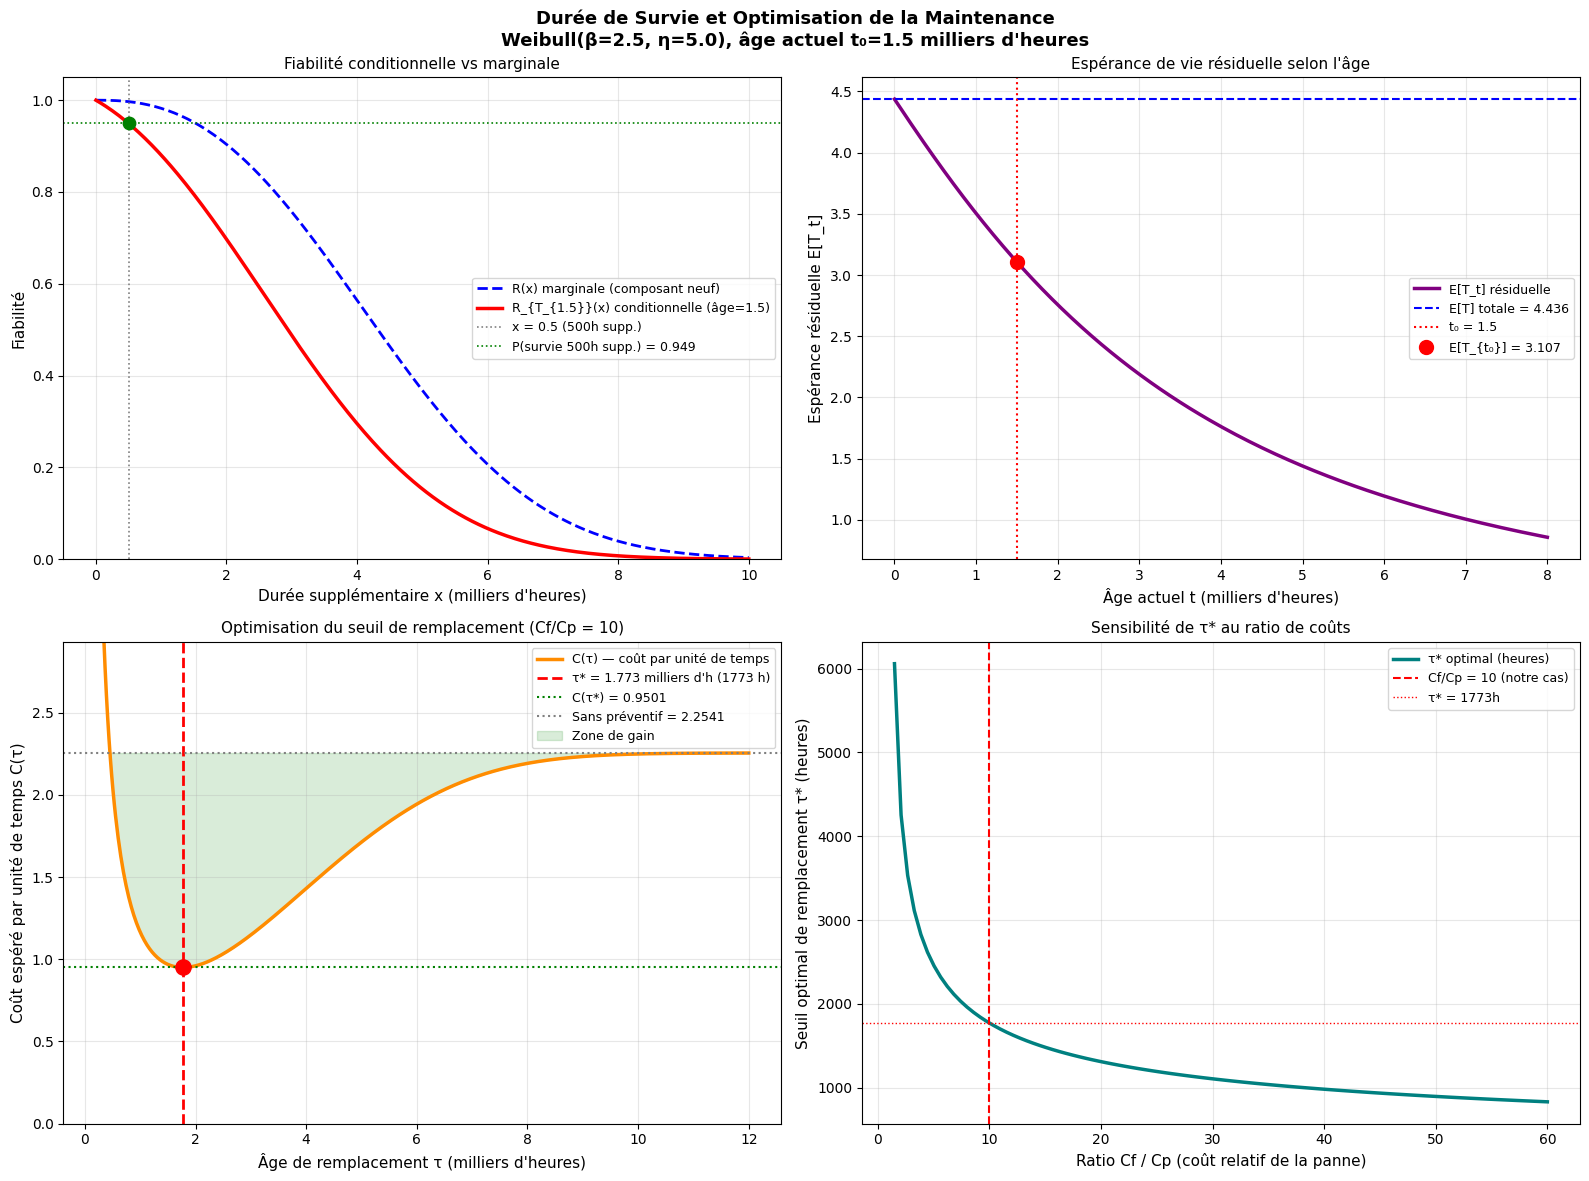

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar

# ══════════════════════════════════════════════════════════════════════════════
# PARAMÈTRES DU MODÈLE
# ══════════════════════════════════════════════════════════════════════════════
beta = 2.5
eta  = 5.0
t0   = 1.5      # âge actuel du serveur (milliers d'heures)
dx   = 0.5      # durée supplémentaire à évaluer (milliers d'heures)
Cp   = 1.0      # coût préventif (unité de référence)
Cf   = 10.0     # coût curatif = 10 × Cp

def R(t):
    """Fiabilité Weibull : R(t) = exp(-(t/eta)^beta)"""
    return np.exp(-(t / eta)**beta)

def f(t):
    """Densité Weibull"""
    return (beta / eta) * (t / eta)**(beta - 1) * np.exp(-(t / eta)**beta)

def lam(t):
    """Taux de défaillance Weibull"""
    return (beta / eta) * (t / eta)**(beta - 1)

# ══════════════════════════════════════════════════════════════════════════════
# QUESTION 1 — Probabilité de survie 500h supplémentaires
# ══════════════════════════════════════════════════════════════════════════════
R_t0    = R(t0)
R_t0_dx = R(t0 + dx)
P_survie = R_t0_dx / R_t0

print("=" * 60)
print("  QUESTION 1 — Probabilité de survie conditionnelle")
print("=" * 60)
print(f"  t0 = {t0} milliers d'heures (âge actuel)")
print(f"  Δt = {dx} milliers d'heures (durée à évaluer)")
print(f"  R_T({t0})        = {R_t0:.6f}")
print(f"  R_T({t0+dx})     = {R_t0_dx:.6f}")
print(f"  P(T>{t0+dx}|T>{t0}) = {P_survie:.6f}  ({P_survie*100:.2f} %)")

# ══════════════════════════════════════════════════════════════════════════════
# QUESTION 2 — Espérance de vie résiduelle E[T_t0]
# ══════════════════════════════════════════════════════════════════════════════
# Intégrale numérique : ∫_{t0}^{+∞} R(u) du
# On tronque à 50 (fiabilité négligeable au-delà)
integrale, err = quad(R, t0, 50)
E_residuelle = integrale / R_t0

# Espérance de vie totale (pour comparaison) : E[T] = ∫_0^∞ R(u) du
E_totale, _ = quad(R, 0, 50)

# Espérance de vie résiduelle pour plusieurs valeurs de t
ages = np.linspace(0, 8, 200)
E_res = []
for t_age in ages:
    Rt_age = R(t_age)
    if Rt_age < 1e-10:
        E_res.append(0)
    else:
        integ, _ = quad(R, t_age, 50)
        E_res.append(integ / Rt_age)
E_res = np.array(E_res)

print("\n" + "=" * 60)
print("  QUESTION 2 — Espérance de vie résiduelle")
print("=" * 60)
print(f"  E[T] (espérance totale)          = {E_totale:.4f} milliers d'heures")
print(f"  ∫_{{t0}}^∞ R(u)du                  = {integrale:.6f}")
print(f"  E[T_t0] = intégrale / R(t0)      = {E_residuelle:.4f} milliers d'heures")
print(f"  Soit environ {E_residuelle*1000:.0f} heures de vie résiduelle")
print(f"  (erreur numérique estimée : {err:.2e})")

# ══════════════════════════════════════════════════════════════════════════════
# QUESTION 3 — Optimisation du seuil de remplacement préventif
# ══════════════════════════════════════════════════════════════════════════════
def cout_par_unite_temps(tau):
    """Coût espéré par unité de temps pour un remplacement préventif à l'âge tau."""
    if tau <= 0:
        return np.inf
    R_tau = R(tau)
    # Numérateur : coût espéré par cycle
    numerateur = Cp * R_tau + Cf * (1 - R_tau)
    # Dénominateur : durée moyenne du cycle = ∫_0^tau R(u) du
    denominateur, _ = quad(R, 0, tau)
    if denominateur < 1e-12:
        return np.inf
    return numerateur / denominateur

# Calcul sur une grille de tau
tau_grid   = np.linspace(0.2, 12, 500)
cout_grid  = np.array([cout_par_unite_temps(tau) for tau in tau_grid])

# Optimisation numérique (minimum exact)
result  = minimize_scalar(cout_par_unite_temps, bounds=(0.5, 10), method='bounded')
tau_opt = result.x
cout_opt = result.fun

# Coût sans maintenance préventive (remplacement seulement sur panne)
cout_sans_prev = Cf / E_totale   # = Cf × µ = coût panne / espérance

print("\n" + "=" * 60)
print("  QUESTION 3 — Optimisation de la maintenance")
print("=" * 60)
print(f"  Cp (coût préventif)              = {Cp:.1f} unité")
print(f"  Cf (coût curatif)                = {Cf:.1f} unités")
print(f"  τ* optimal (remplacement préventif) = {tau_opt:.4f} milliers d'heures")
print(f"  τ* en heures                     = {tau_opt*1000:.0f} heures")
print(f"  Coût minimal C(τ*)               = {cout_opt:.4f} unité/millier d'heures")
print(f"  Coût sans maintenance préventive = {cout_sans_prev:.4f} unité/millier d'heures")
print(f"  Économie réalisée                = {(1-cout_opt/cout_sans_prev)*100:.1f} %")
print(f"\n  → Recommandation : remplacer les serveurs à {tau_opt:.2f} milliers d'heures")
print(f"    soit tous les {tau_opt*1000:.0f} heures environ.")

# Sensibilité au ratio Cf/Cp
ratios = [3, 5, 10, 20, 50]
print("\n  Sensibilité au ratio Cf/Cp :")
print(f"  {'Ratio Cf/Cp':>12} | {'τ* (milliers h)':>16} | {'τ* (heures)':>12}")
print("  " + "-" * 46)
for ratio in ratios:
    def c_ratio(tau):
        if tau <= 0: return np.inf
        Rt = R(tau)
        num = 1.0 * Rt + ratio * (1 - Rt)
        den, _ = quad(R, 0, tau)
        return num / den if den > 1e-12 else np.inf
    res = minimize_scalar(c_ratio, bounds=(0.5, 12), method='bounded')
    marker = " ★" if ratio == 10 else ""
    print(f"  {ratio:>12} | {res.x:>16.4f} | {res.x*1000:>12.0f}{marker}")

# ══════════════════════════════════════════════════════════════════════════════
# FIGURES
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    f"Durée de Survie et Optimisation de la Maintenance\n"
    f"Weibull(β={beta}, η={eta}), âge actuel t₀={t0} milliers d'heures",
    fontsize=13, fontweight='bold'
)

t_plot = np.linspace(0.001, 12, 600)

# ── 1. Fiabilité conditionnelle R_{T_t0}(x) ──────────────────────────────────
ax = axes[0, 0]
x_plot = np.linspace(0, 10, 400)
R_cond = R(t0 + x_plot) / R_t0
R_marg = R(x_plot)

ax.plot(x_plot, R_marg,  'b--', lw=2, label='R(x) marginale (composant neuf)')
ax.plot(x_plot, R_cond,  'r-',  lw=2.5, label=f'R_{{T_{{{t0}}}}}(x) conditionnelle (âge={t0})')
ax.axvline(dx, color='gray',   lw=1.2, linestyle=':', label=f'x = {dx} (500h supp.)')
ax.axhline(P_survie, color='green', lw=1.2, linestyle=':',
           label=f'P(survie 500h supp.) = {P_survie:.3f}')
ax.scatter([dx], [P_survie], color='green', s=80, zorder=5)
ax.set_xlabel("Durée supplémentaire x (milliers d'heures)", fontsize=11)
ax.set_ylabel("Fiabilité", fontsize=11)
ax.set_title("Fiabilité conditionnelle vs marginale", fontsize=11)
ax.legend(fontsize=9)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)

# ── 2. Espérance de vie résiduelle E[T_t] en fonction de t ──────────────────
ax = axes[0, 1]
ax.plot(ages, E_res, 'purple', lw=2.5, label='E[T_t] résiduelle')
ax.axhline(E_totale, color='blue', lw=1.5, linestyle='--',
           label=f'E[T] totale = {E_totale:.3f}')
ax.axvline(t0, color='red', lw=1.5, linestyle=':',
           label=f't₀ = {t0}')
ax.scatter([t0], [E_residuelle], color='red', s=100, zorder=5,
           label=f'E[T_{{t₀}}] = {E_residuelle:.3f}')
ax.set_xlabel("Âge actuel t (milliers d'heures)", fontsize=11)
ax.set_ylabel("Espérance résiduelle E[T_t]", fontsize=11)
ax.set_title("Espérance de vie résiduelle selon l'âge", fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# ── 3. Courbe de coût C(τ) et optimum ────────────────────────────────────────
ax = axes[1, 0]
ax.plot(tau_grid, cout_grid, 'darkorange', lw=2.5, label='C(τ) — coût par unité de temps')
ax.axvline(tau_opt, color='red', lw=2, linestyle='--',
           label=f'τ* = {tau_opt:.3f} milliers d\'h ({tau_opt*1000:.0f} h)')
ax.axhline(cout_opt, color='green', lw=1.5, linestyle=':',
           label=f'C(τ*) = {cout_opt:.4f}')
ax.axhline(cout_sans_prev, color='gray', lw=1.5, linestyle=':',
           label=f'Sans préventif = {cout_sans_prev:.4f}')
ax.scatter([tau_opt], [cout_opt], color='red', s=120, zorder=5)
ax.fill_between(tau_grid, cout_grid, cout_sans_prev,
                where=(cout_grid < cout_sans_prev),
                alpha=0.15, color='green', label='Zone de gain')
ax.set_xlabel("Âge de remplacement τ (milliers d'heures)", fontsize=11)
ax.set_ylabel("Coût espéré par unité de temps C(τ)", fontsize=11)
ax.set_title(f"Optimisation du seuil de remplacement (Cf/Cp = {int(Cf/Cp)})", fontsize=11)
ax.legend(fontsize=9)
ax.set_ylim(0, Cf / E_totale * 1.3)
ax.grid(alpha=0.3)

# ── 4. Sensibilité : τ* en fonction du ratio Cf/Cp ───────────────────────────
ax = axes[1, 1]
ratios_cont = np.linspace(1.5, 60, 100)
tau_opts = []
for ratio in ratios_cont:
    def c_r(tau):
        if tau <= 0: return np.inf
        Rt = R(tau)
        num = 1.0 * Rt + ratio * (1 - Rt)
        den, _ = quad(R, 0, tau)
        return num / den if den > 1e-12 else np.inf
    res = minimize_scalar(c_r, bounds=(0.5, 12), method='bounded')
    tau_opts.append(res.x)
tau_opts = np.array(tau_opts)

ax.plot(ratios_cont, tau_opts * 1000, 'teal', lw=2.5,
        label='τ* optimal (heures)')
ax.axvline(10, color='red', lw=1.5, linestyle='--', label='Cf/Cp = 10 (notre cas)')
ax.axhline(tau_opt * 1000, color='red', lw=1, linestyle=':',
           label=f'τ* = {tau_opt*1000:.0f}h')
ax.set_xlabel("Ratio Cf / Cp (coût relatif de la panne)", fontsize=11)
ax.set_ylabel("Seuil optimal de remplacement τ* (heures)", fontsize=11)
ax.set_title("Sensibilité de τ* au ratio de coûts", fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("maintenance_optimisation.png", dpi=150, bbox_inches='tight')
plt.show()

#**Disponibilité A(τ ) en fonction de l’âge de remplacement τ (TR = 4h,TRP = 0,5h)**

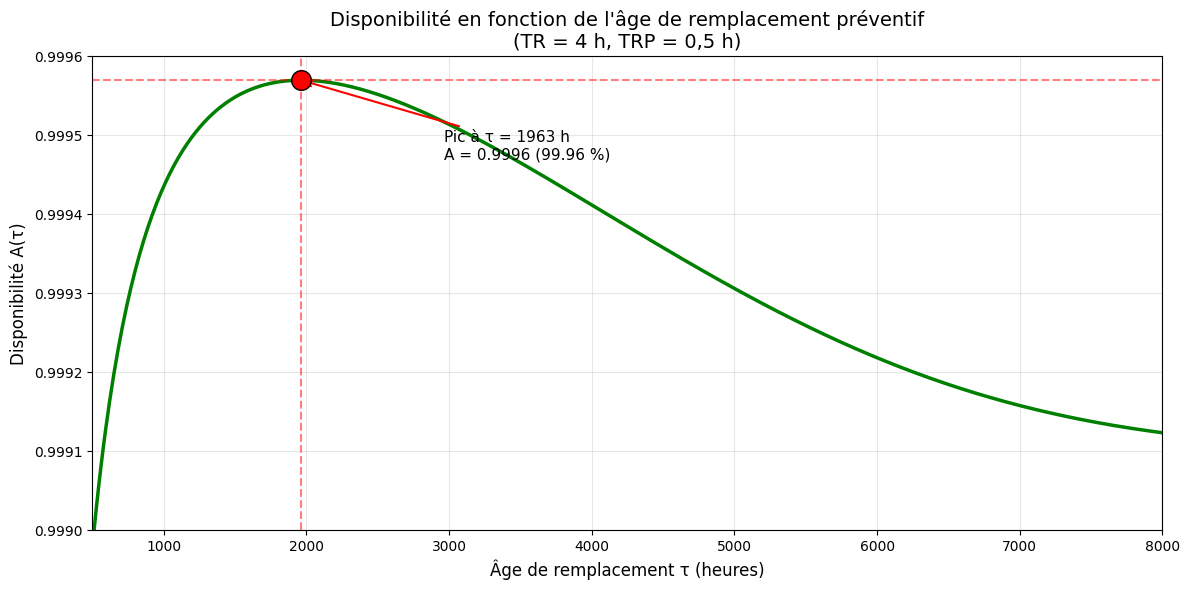

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar

# ========== PARAMÈTRES ==========
beta  = 2.5
eta_h = 5000
TR    = 4
TRP   = 0.5
Cp    = 1
Cf    = 10

def R_h(t):
    return np.exp(-(t / eta_h) ** beta)

def temps_bon_fonctionnement_h(tau):
    result, _ = quad(R_h, 0, tau)
    return result

def disponibilite_h(tau):
    if tau <= 0:
        return 0
    tbf   = temps_bon_fonctionnement_h(tau)
    denom = tbf + TR * (1 - R_h(tau)) + TRP * R_h(tau)
    if denom == 0:
        return 0
    return tbf / denom

# Optimum disponibilité
res_dispo     = minimize_scalar(lambda x: -disponibilite_h(x), bounds=(500, 8000), method='bounded')
tau_opt_dispo = res_dispo.x
dispo_max     = disponibilite_h(tau_opt_dispo)

# Tracé
tau_heures   = np.linspace(500, 8000, 500)
dispo_values = np.array([disponibilite_h(t) for t in tau_heures])

plt.figure(figsize=(12, 6))
plt.plot(tau_heures, dispo_values, 'g-', linewidth=2.5)
plt.scatter([tau_opt_dispo], [dispo_max], color='red', s=200, zorder=5, edgecolors='black')
plt.annotate(
    f'Pic à τ = {tau_opt_dispo:.0f} h\nA = {dispo_max:.4f} ({dispo_max*100:.2f} %)',
    xy=(tau_opt_dispo, dispo_max),
    xytext=(tau_opt_dispo + 1000, dispo_max - 0.0001),
    arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
    fontsize=11,
)
plt.axvline(tau_opt_dispo, color='red', linestyle='--', alpha=0.5)
plt.axhline(dispo_max,     color='red', linestyle='--', alpha=0.5)
plt.xlabel('Âge de remplacement τ (heures)', fontsize=12)
plt.ylabel('Disponibilité A(τ)',             fontsize=12)
plt.title('Disponibilité en fonction de l\'âge de remplacement préventif\n(TR = 4 h, TRP = 0,5 h)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.xlim(500, 8000)
plt.ylim(0.9990, 0.9996)
plt.tight_layout()
plt.savefig('courbe_disponibilite.png', dpi=150, bbox_inches='tight')
plt.show()

#**Évolution comparée du coût normalisé C(τ )/Cmin et de la disponibilité A(τ )**

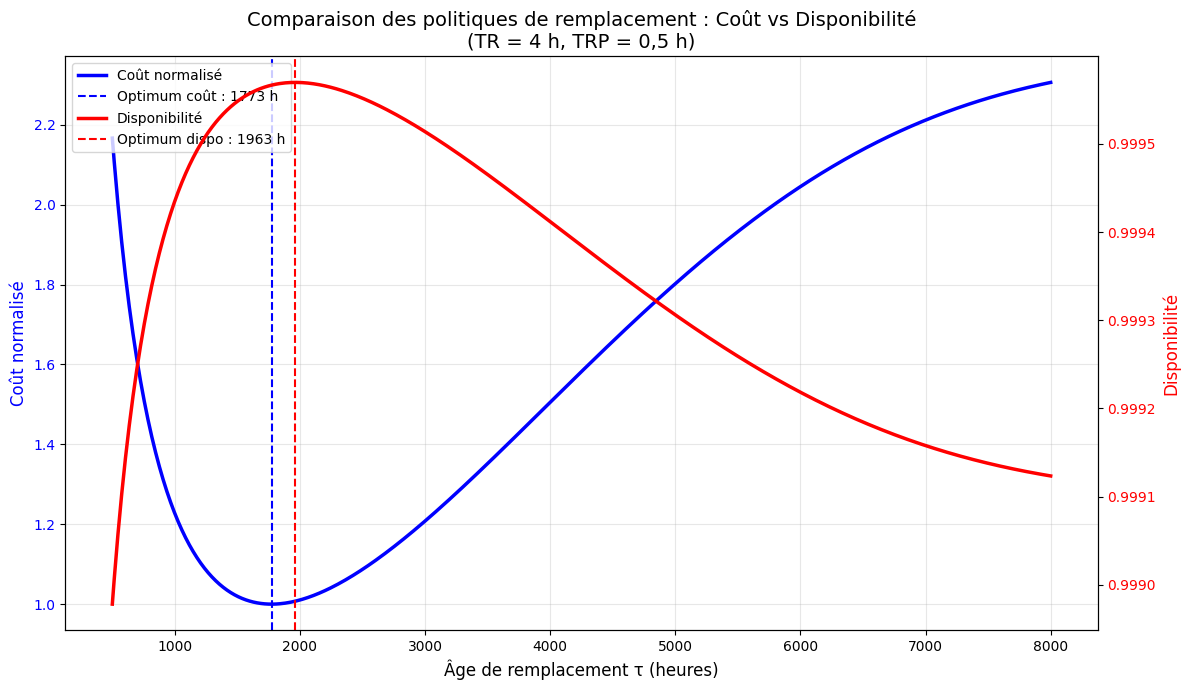

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar

# ========== PARAMÈTRES ==========
beta  = 2.5
eta_h = 5000
TR    = 4
TRP   = 0.5
Cp    = 1
Cf    = 10

def R_h(t):
    return np.exp(-(t / eta_h) ** beta)

def temps_bon_fonctionnement_h(tau):
    result, _ = quad(R_h, 0, tau)
    return result

def cout_h(tau, cf=Cf):
    if tau <= 0:
        return np.inf
    tbf = temps_bon_fonctionnement_h(tau)
    if tbf == 0:
        return np.inf
    return (Cp * R_h(tau) + cf * (1 - R_h(tau))) / tbf

def disponibilite_h(tau):
    if tau <= 0:
        return 0
    tbf   = temps_bon_fonctionnement_h(tau)
    denom = tbf + TR * (1 - R_h(tau)) + TRP * R_h(tau)
    if denom == 0:
        return 0
    return tbf / denom

# Optimums
tau_opt_cout  = minimize_scalar(cout_h, bounds=(500, 8000), method='bounded').x
tau_opt_dispo = minimize_scalar(lambda x: -disponibilite_h(x), bounds=(500, 8000), method='bounded').x

# Données
tau_heures     = np.linspace(500, 8000, 500)
cout_values    = np.array([cout_h(t)          for t in tau_heures])
dispo_values   = np.array([disponibilite_h(t) for t in tau_heures])
cout_normalise = cout_values / np.min(cout_values)

# Tracé
fig, ax1 = plt.subplots(figsize=(12, 7))

ax1.plot(tau_heures, cout_normalise, 'b-', linewidth=2.5, label='Coût normalisé')
ax1.set_xlabel('Âge de remplacement τ (heures)', fontsize=12)
ax1.set_ylabel('Coût normalisé', color='b', fontsize=12)
ax1.tick_params(axis='y', labelcolor='b')
ax1.axvline(tau_opt_cout, color='b', linestyle='--', linewidth=1.5,
            label=f'Optimum coût : {tau_opt_cout:.0f} h')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(tau_heures, dispo_values, 'r-', linewidth=2.5, label='Disponibilité')
ax2.set_ylabel('Disponibilité', color='r', fontsize=12)
ax2.tick_params(axis='y', labelcolor='r')
ax2.axvline(tau_opt_dispo, color='r', linestyle='--', linewidth=1.5,
            label=f'Optimum dispo : {tau_opt_dispo:.0f} h')

plt.title('Comparaison des politiques de remplacement : Coût vs Disponibilité\n(TR = 4 h, TRP = 0,5 h)', fontsize=14)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.savefig('comparaison_optimums.png', dpi=150, bbox_inches='tight')
plt.show()

#**Traitement des données censurées – Estimateur de KaplanMeier**

#**Fiabilité théorique, estimateur de Kaplan-Meier (avec IC 95%) et estimateur naïf**

Taux de censure = 73.9%


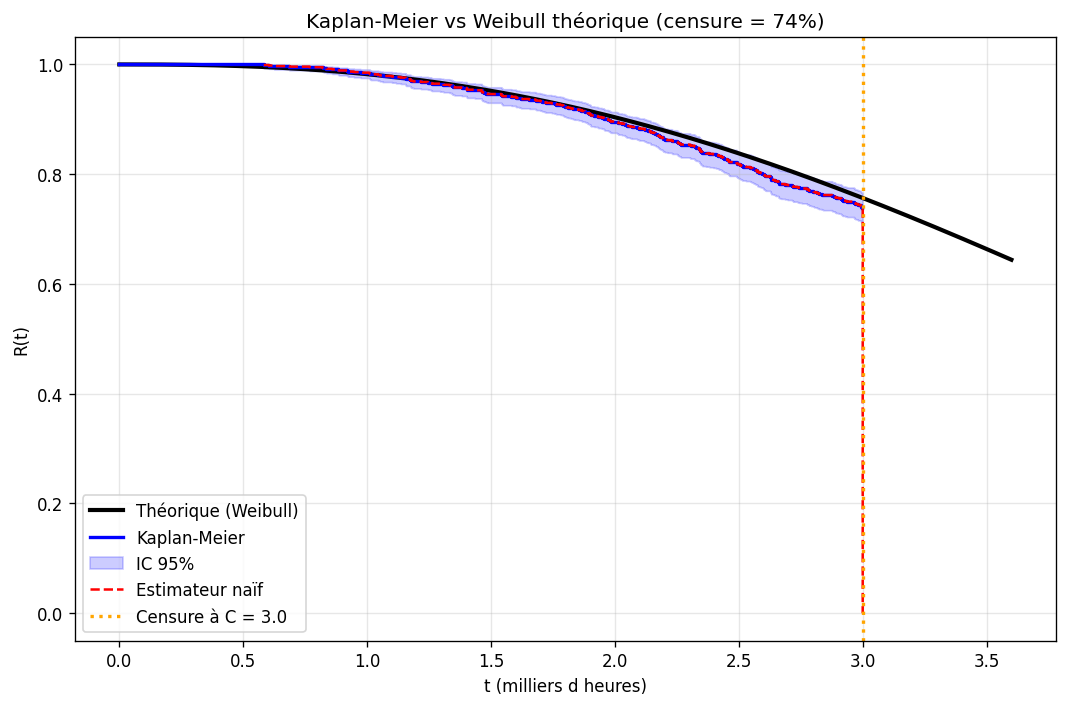

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar
from scipy.special import gamma
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120

# ============================================
# PARAMÈTRES (échantillon initial)
# ============================================
beta_vrai = 2.5
eta_vrai  = 5.0          # milliers d'heures
n = 1000                 # taille du parc
np.random.seed(42)

# Génération des durées de vie complètes (non censurées)
T_vrai = eta_vrai * np.random.weibull(beta_vrai, n)

# Censure à C = 3 milliers d'heures (fin d'étude)
C = 3.0
T_obs = np.minimum(T_vrai, C)
delta = (T_vrai <= C).astype(int)   # 1 = panne observée, 0 = censuré

taux_censure = 100 * (1 - np.mean(delta))
print(f"Taux de censure = {taux_censure:.1f}%")

# ============================================
# Fonction Kaplan-Meier
# ============================================
def kaplan_meier(T_obs, delta):
    ordre = np.argsort(T_obs)
    T_sort = T_obs[ordre]
    d_sort = delta[ordre]

    n_i = len(T_sort)
    R_km = 1.0
    t_km = [0.0]
    R_liste = [1.0]
    var_sum = 0.0
    var_liste = [0.0]

    i = 0
    while i < len(T_sort):
        t_i = T_sort[i]
        d_i = 0
        c_i = 0
        j = i
        while j < len(T_sort) and T_sort[j] == t_i:
            if d_sort[j] == 1:
                d_i += 1
            else:
                c_i += 1
            j += 1

        if d_i > 0:
            R_km = R_km * (1 - d_i / n_i)
            var_sum += d_i / (n_i * (n_i - d_i)) if n_i > d_i else 0
            t_km.append(t_i)
            R_liste.append(R_km)
            var_liste.append(R_km**2 * var_sum)

        n_i -= (d_i + c_i)
        i = j

    return np.array(t_km), np.array(R_liste), np.array(var_liste)

t_km, R_km, var_km = kaplan_meier(T_obs, delta)

# Intervalles de confiance à 95% (méthode log-log)
IC_bas = np.zeros_like(R_km)
IC_haut = np.zeros_like(R_km)
z = 1.96
for k in range(len(R_km)):
    if R_km[k] > 0 and R_km[k] < 1 and var_km[k] > 0:
        se = np.sqrt(var_km[k])
        sigma = se / (R_km[k] * abs(np.log(R_km[k])))
        IC_bas[k]  = R_km[k] ** np.exp( z * sigma)
        IC_haut[k] = R_km[k] ** np.exp(-z * sigma)
    else:
        IC_bas[k] = IC_haut[k] = R_km[k]

# ============================================
# Estimateur naïf (ignore la censure)
# ============================================
t_naif = np.sort(T_obs)
R_naif = np.array([np.mean(T_obs > t) for t in t_naif])

# ============================================
# Fiabilité théorique (Weibull)
# ============================================
t_th = np.linspace(0, C*1.2, 500)
R_th = np.exp(-(t_th / eta_vrai) ** beta_vrai)

# ============================================
# GRAPHIQUE 1 : KM vs Weibull théorique vs naïf
# ============================================
plt.figure(figsize=(9, 6))
plt.plot(t_th, R_th, 'k-', linewidth=2.5, label='Théorique (Weibull)')
plt.step(t_km, R_km, 'b-', linewidth=2, where='post', label='Kaplan-Meier')
plt.fill_between(t_km, IC_bas, IC_haut, step='post', alpha=0.2, color='blue', label='IC 95%')
plt.step(t_naif, R_naif, 'r--', linewidth=1.5, where='post', label='Estimateur naïf')
plt.axvline(C, color='orange', linestyle=':', linewidth=2, label=f'Censure à C = {C}')
plt.xlabel('t (milliers d heures)')
plt.ylabel('R(t)')
plt.title(f'Kaplan-Meier vs Weibull théorique (censure = {taux_censure:.0f}%)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('km_vs_weibull.png', dpi=150)
plt.show()


#**Papier de Weibull sur les résultats de Kaplan-Meier**

Taux de censure = 73.9%


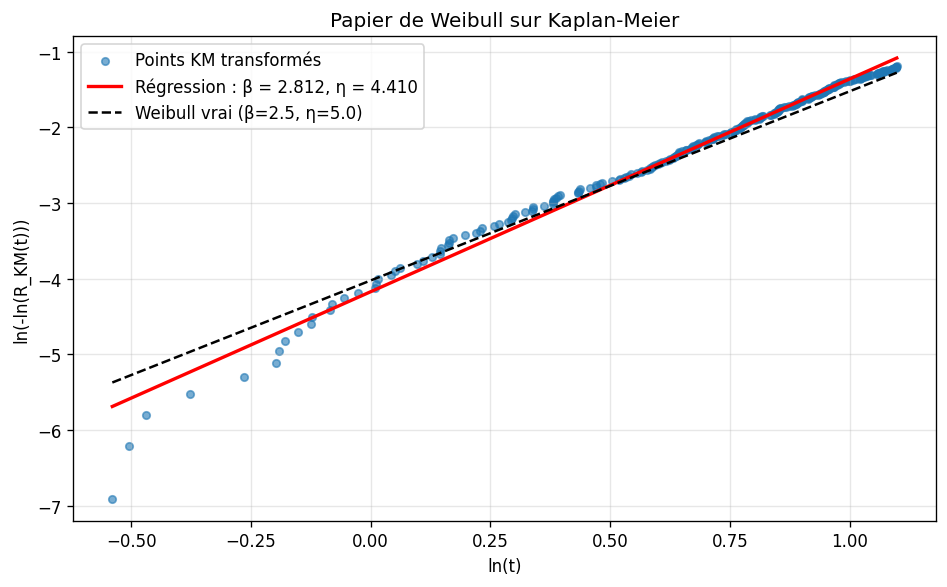

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar
from scipy.special import gamma
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120

# ============================================
# PARAMÈTRES (échantillon initial)
# ============================================
beta_vrai = 2.5
eta_vrai  = 5.0          # milliers d'heures
n = 1000                 # taille du parc
np.random.seed(42)

# Génération des durées de vie complètes (non censurées)
T_vrai = eta_vrai * np.random.weibull(beta_vrai, n)

# Censure à C = 3 milliers d'heures (fin d'étude)
C = 3.0
T_obs = np.minimum(T_vrai, C)
delta = (T_vrai <= C).astype(int)   # 1 = panne observée, 0 = censuré

taux_censure = 100 * (1 - np.mean(delta))
print(f"Taux de censure = {taux_censure:.1f}%")

# ============================================
# Fonction Kaplan-Meier
# ============================================
def kaplan_meier(T_obs, delta):
    ordre = np.argsort(T_obs)
    T_sort = T_obs[ordre]
    d_sort = delta[ordre]

    n_i = len(T_sort)
    R_km = 1.0
    t_km = [0.0]
    R_liste = [1.0]
    var_sum = 0.0
    var_liste = [0.0]

    i = 0
    while i < len(T_sort):
        t_i = T_sort[i]
        d_i = 0
        c_i = 0
        j = i
        while j < len(T_sort) and T_sort[j] == t_i:
            if d_sort[j] == 1:
                d_i += 1
            else:
                c_i += 1
            j += 1

        if d_i > 0:
            R_km = R_km * (1 - d_i / n_i)
            var_sum += d_i / (n_i * (n_i - d_i)) if n_i > d_i else 0
            t_km.append(t_i)
            R_liste.append(R_km)
            var_liste.append(R_km**2 * var_sum)

        n_i -= (d_i + c_i)
        i = j

    return np.array(t_km), np.array(R_liste), np.array(var_liste)

t_km, R_km, var_km = kaplan_meier(T_obs, delta)

# Intervalles de confiance à 95% (méthode log-log)
IC_bas = np.zeros_like(R_km)
IC_haut = np.zeros_like(R_km)
z = 1.96
for k in range(len(R_km)):
    if R_km[k] > 0 and R_km[k] < 1 and var_km[k] > 0:
        se = np.sqrt(var_km[k])
        sigma = se / (R_km[k] * abs(np.log(R_km[k])))
        IC_bas[k]  = R_km[k] ** np.exp( z * sigma)
        IC_haut[k] = R_km[k] ** np.exp(-z * sigma)
    else:
        IC_bas[k] = IC_haut[k] = R_km[k]

# ============================================
# Estimateur naïf (ignore la censure)
# ============================================
t_naif = np.sort(T_obs)
R_naif = np.array([np.mean(T_obs > t) for t in t_naif])

# ============================================
# Fiabilité théorique (Weibull)
# ============================================
t_th = np.linspace(0, C*1.2, 500)
R_th = np.exp(-(t_th / eta_vrai) ** beta_vrai)

# ============================================
# GRAPHIQUE : Papier de Weibull sur les résultats KM
# ============================================
mask = (R_km[1:] > 0) & (R_km[1:] < 1)
t_w = t_km[1:][mask]
y_w = np.log(-np.log(R_km[1:][mask]))
x_w = np.log(t_w)

coeffs = np.polyfit(x_w, y_w, 1)
beta_est = coeffs[0]
eta_est = np.exp(-coeffs[1] / coeffs[0])

x_line = np.linspace(x_w.min(), x_w.max(), 100)
y_line = coeffs[0] * x_line + coeffs[1]

plt.figure(figsize=(8, 5))
plt.scatter(x_w, y_w, s=20, alpha=0.6, label='Points KM transformés')
plt.plot(x_line, y_line, 'r-', linewidth=2,
         label=f'Régression : β = {beta_est:.3f}, η = {eta_est:.3f}')
y_vrai = beta_vrai * x_line - beta_vrai * np.log(eta_vrai)
plt.plot(x_line, y_vrai, 'k--', linewidth=1.5, label=f'Weibull vrai (β={beta_vrai}, η={eta_vrai})')
plt.xlabel('ln(t)')
plt.ylabel('ln(-ln(R_KM(t)))')
plt.title('Papier de Weibull sur Kaplan-Meier')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('km_papier_weibull.png', dpi=150)
plt.show()

# **Modélisation de la fiabilité sur données réelles**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from scipy.stats import weibull_min
from mpl_toolkits.mplot3d import Axes3D
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from scipy.stats import weibull_min
from scipy.special import gamma
from scipy.optimize import fsolve

In [ ]:
# Chargement des données
subset = "FD002"
base_url = "https://raw.githubusercontent.com/EyaNajlaoui/Fiabilite-ML-Moteurs/main/data/"

train_url = f"{base_url}train_{subset}.txt"
test_url = f"{base_url}test_{subset}.txt"
rul_url = f"{base_url}RUL_{subset}.txt"

# Charger et nettoyer les données
train_data = pd.read_csv(train_url, sep=" ", header=None, engine='python').dropna(axis=1, how='all')
test_data = pd.read_csv(test_url, sep=" ", header=None, engine='python').dropna(axis=1, how='all')
rul_data = pd.read_csv(rul_url, sep=" ", header=None, engine='python').dropna(axis=1, how='all')

# Nommer les colonnes
columns = ['unit_id','cycle','op_setting1','op_setting2','op_setting3'] + [f'sensor_{i}' for i in range(1,22)]
train_data.columns = columns
test_data.columns = columns
rul_data.columns = ['RUL']

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)
print("RUL shape:", rul_data.shape)
train_data.head(5)

Train shape: (53759, 26)
Test shape: (33991, 26)
RUL shape: (259, 1)


,unit_id,cycle,op_setting1,op_setting2,op_setting3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286


Calcul de la log-vraisemblance sur la grille...

Maximum trouvé sur la grille :
  β = 4.3846
  η = 225.64
  Log-vraisemblance = -1382.32

Génération de la figure 1 : Surface 3D...


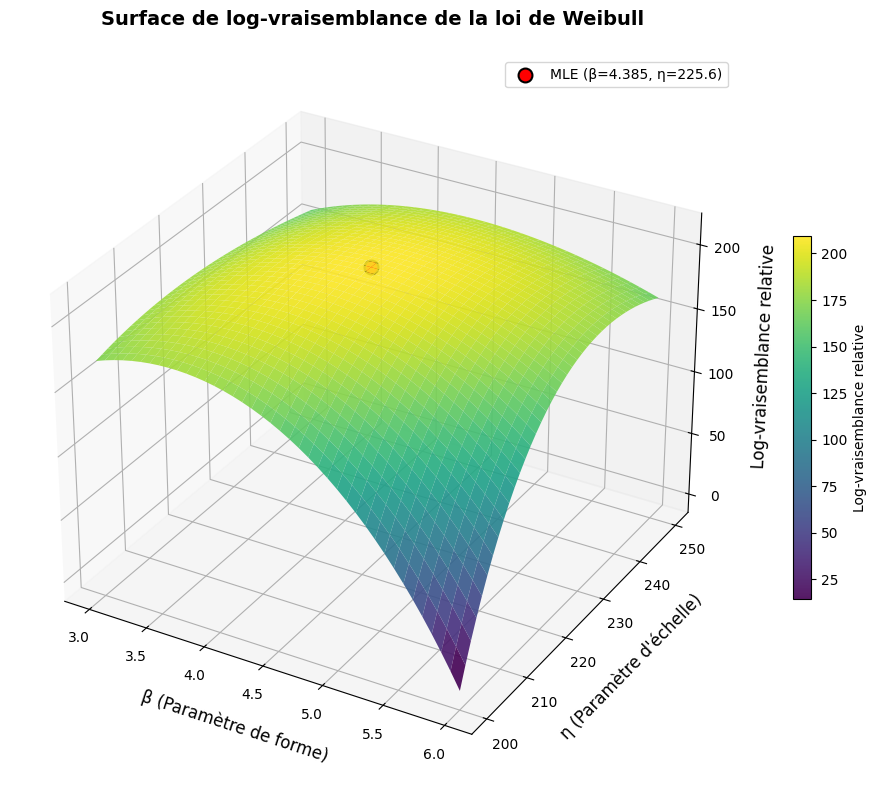

Génération de la figure 2 : Courbes de niveau...


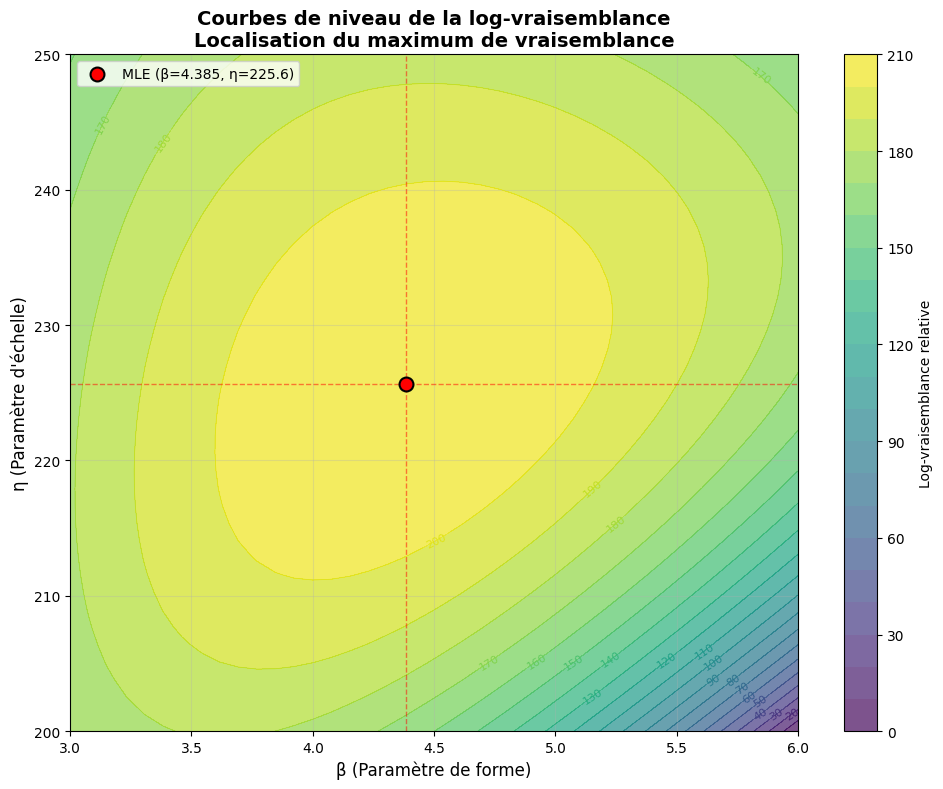


RÉSULTATS DE L'ANALYSE DE LOG-VRAISEMBLANCE

Paramètres optimaux (MLE) :
   • β (paramètre de forme)  = 4.3846
   • η (paramètre d'échelle) = 225.64 cycles
   • Log-vraisemblance max    = -1382.32





In [ ]:
# FONCTION DE LOG-VRAISEMBLANCE

def log_likelihood(beta, eta, data):

    n = len(data)
    # Éviter les valeurs invalides
    if beta <= 0 or eta <= 0:
        return -np.inf

    # Calcul de la log-vraisemblance
    term1 = n * np.log(beta) - n * beta * np.log(eta)
    term2 = (beta - 1) * np.sum(np.log(data))
    term3 = -np.sum((data / eta) ** beta)

    return term1 + term2 + term3

# CRÉATION DE LA GRILLE DE PARAMÈTRES

beta_vals = np.linspace(3.0, 6.0, 40)
eta_vals = np.linspace(200, 250, 40)

# Création de la grille
B, E = np.meshgrid(beta_vals, eta_vals)

# Calcul de la log-vraisemblance sur la grille
print("Calcul de la log-vraisemblance sur la grille...")
Z = np.zeros_like(B)

for i in range(len(beta_vals)):
    for j in range(len(eta_vals)):
        Z[j, i] = log_likelihood(beta_vals[i], eta_vals[j], lifetimes)

# Normalisation pour la visualisation
Z_rel = Z - np.min(Z)

# Trouver le maximum (MLE)
idx_max = np.unravel_index(np.argmax(Z), Z.shape)
beta_mle = beta_vals[idx_max[1]]
eta_mle = eta_vals[idx_max[0]]
logL_max = Z[idx_max]

print(f"\nMaximum trouvé sur la grille :")
print(f"  β = {beta_mle:.4f}")
print(f"  η = {eta_mle:.2f}")
print(f"  Log-vraisemblance = {logL_max:.2f}")

# FIGURE 1 - SURFACE 3D COMPLÈTE
print("\nGénération de la figure 1 : Surface 3D...")

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Surface avec colormap
surf = ax.plot_surface(B, E, Z_rel, cmap='viridis', alpha=0.9,
                       edgecolor='none', linewidth=0)

# Point du maximum (MLE)
ax.scatter(beta_mle, eta_mle, Z_rel[idx_max],
           color='red', s=100, label=f'MLE (β={beta_mle:.3f}, η={eta_mle:.1f})',
           edgecolor='black', linewidth=1.5)

# Labels
ax.set_xlabel('β (Paramètre de forme)', fontsize=12, labelpad=10)
ax.set_ylabel('η (Paramètre d\'échelle)', fontsize=12, labelpad=10)
ax.set_zlabel('Log-vraisemblance relative', fontsize=12, labelpad=10)
ax.set_title('Surface de log-vraisemblance de la loi de Weibull\n', fontsize=14, fontweight='bold')

# Ajout d'une barre de couleur
cbar = fig.colorbar(surf, ax=ax, shrink=0.5, aspect=20)
cbar.set_label('Log-vraisemblance relative', fontsize=10)

ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('figure_logvraisemblance_3d.png', dpi=150, bbox_inches='tight')
plt.show()

# FIGURE 2 - COURBES DE NIVEAU (CONTOUR PLOT)
print("Génération de la figure 2 : Courbes de niveau...")

plt.figure(figsize=(10, 8))

# Courbes de niveau
contour = plt.contour(B, E, Z_rel, levels=20, cmap='viridis', linewidths=0.5)
plt.clabel(contour, inline=True, fontsize=8, fmt='%.0f')

# Contour fill
contour_filled = plt.contourf(B, E, Z_rel, levels=20, cmap='viridis', alpha=0.7)

# Point MLE
plt.scatter(beta_mle, eta_mle, color='red', s=100,
            label=f'MLE (β={beta_mle:.3f}, η={eta_mle:.1f})',
            edgecolor='black', linewidth=1.5, zorder=5)

# Lignes horizontales et verticales
plt.axhline(y=eta_mle, color='red', linestyle='--', alpha=0.5, linewidth=1)
plt.axvline(x=beta_mle, color='red', linestyle='--', alpha=0.5, linewidth=1)

# Labels et titres
plt.xlabel('β (Paramètre de forme)', fontsize=12)
plt.ylabel('η (Paramètre d\'échelle)', fontsize=12)
plt.title('Courbes de niveau de la log-vraisemblance\n' +
          'Localisation du maximum de vraisemblance', fontsize=14, fontweight='bold')

# Barre de couleur
cbar = plt.colorbar(contour_filled)
cbar.set_label('Log-vraisemblance relative', fontsize=10)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figure_logvraisemblance_contour.png', dpi=150, bbox_inches='tight')
plt.show()

# AFFICHAGE DES RÉSULTATS
print("\n" + "=" * 60)
print("RÉSULTATS DE L'ANALYSE DE LOG-VRAISEMBLANCE")
print("=" * 60)
print(f"""
Paramètres optimaux (MLE) :
   • β (paramètre de forme)  = {beta_mle:.4f}
   • η (paramètre d'échelle) = {eta_mle:.2f} cycles
   • Log-vraisemblance max    = {logL_max:.2f}


""")

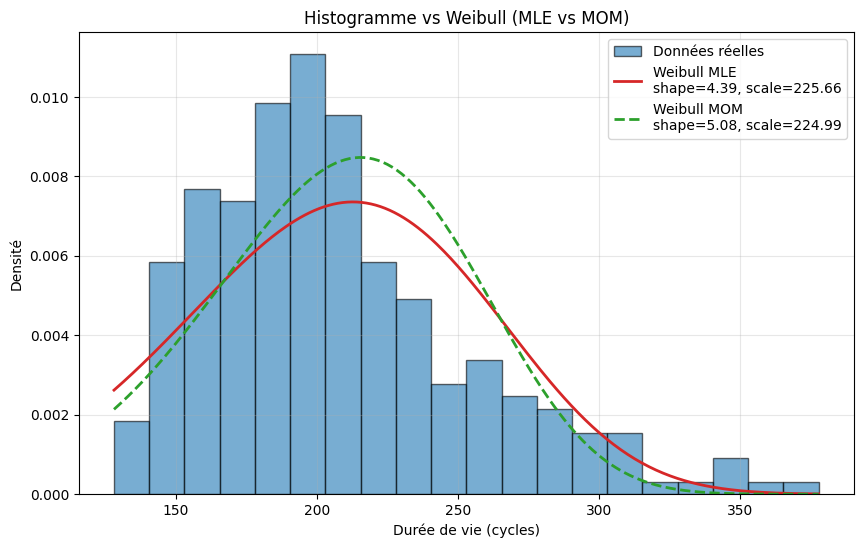

In [ ]:
lifetimes = train_data.groupby('unit_id')['cycle'].max().values
# Ajustement MLE
shape_mle, loc_mle, scale_mle = weibull_min.fit(lifetimes, floc=0)

# Ajustement MOM
mu_emp = np.mean(lifetimes)
sigma_emp = np.std(lifetimes)

def f(beta):
    return sigma_emp / mu_emp - np.sqrt(gamma(1 + 2/beta) - (gamma(1 + 1/beta))**2) / gamma(1 + 1/beta)

beta_mom = fsolve(f, 1.0)[0]
eta_mom = mu_emp / gamma(1 + 1/beta_mom)

# Tracé des densités
x = np.linspace(min(lifetimes), max(lifetimes), 300)

pdf_mle = weibull_min.pdf(x, shape_mle, loc=0, scale=scale_mle)
pdf_mom = weibull_min.pdf(x, beta_mom, loc=0, scale=eta_mom)

plt.figure(figsize=(10,6))

# Histogramme des données réelles
plt.hist(lifetimes, bins=20, density=True, alpha=0.6, color='#1f77b4', edgecolor='black', label='Données réelles')

# Weibull MLE
plt.plot(x, pdf_mle, color='#d62728', lw=2, label=f"Weibull MLE\nshape={shape_mle:.2f}, scale={scale_mle:.2f}")

# Weibull MOM
plt.plot(x, pdf_mom, color='#2ca02c', lw=2, linestyle='--', label=f"Weibull MOM\nshape={beta_mom:.2f}, scale={eta_mom:.2f}")

plt.xlabel("Durée de vie (cycles)")
plt.ylabel("Densité")
plt.title("Histogramme vs Weibull (MLE vs MOM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

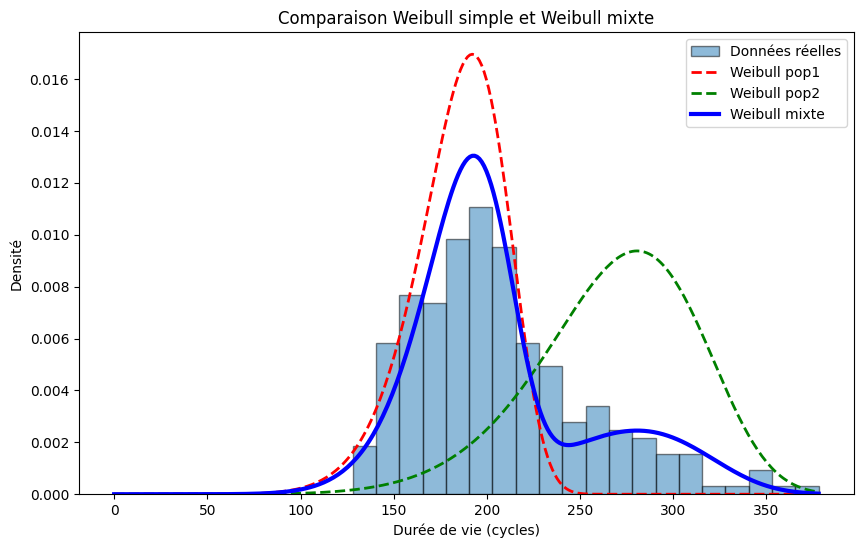

In [ ]:
# Clustering pour identifier 2 populations
durations = lifetimes.reshape(-1,1)
kmeans = KMeans(n_clusters=2, random_state=42).fit(durations)
labels = kmeans.labels_

pop1 = lifetimes[labels==0]
pop2 = lifetimes[labels==1]

# Ajustement Weibull simple pour chaque population
beta1, loc1, eta1 = weibull_min.fit(pop1, floc=0)
beta2, loc2, eta2 = weibull_min.fit(pop2, floc=0)

# Poids de la population 1
w = len(pop1) / len(lifetimes)

# Préparation des courbes pour affichage
x = np.linspace(0, lifetimes.max(), 300)

pdf_pop1 = weibull_min.pdf(x, beta1, 0, eta1)
pdf_pop2 = weibull_min.pdf(x, beta2, 0, eta2)
pdf_mix = w * pdf_pop1 + (1-w) * pdf_pop2

# Figure avec histogramme et Weibull
plt.figure(figsize=(10,6))

# Histogramme des données réelles
plt.hist(lifetimes, bins=20, density=True, alpha=0.5,  color='#1f77b4', edgecolor='black', label='Données réelles')

# Weibull simple pour pop1 et pop2
plt.plot(x, pdf_pop1, 'r--', lw=2, label='Weibull pop1')
plt.plot(x, pdf_pop2, 'g--', lw=2, label='Weibull pop2')

# Weibull mixte
plt.plot(x, pdf_mix, 'b-', lw=3, label='Weibull mixte')

plt.xlabel('Durée de vie (cycles)')
plt.ylabel('Densité')
plt.title('Comparaison Weibull simple et Weibull mixte')
plt.legend()
plt.show()

t = np.linspace(0.001, lifetimes.max()*1.1, 500)

# Fiabilité
R_mle = weibull_min.sf(t, shape_mle, loc=0, scale=scale_mle)
R_mix = w * weibull_min.sf(t, beta1, 0, eta1) + (1-w) * weibull_min.sf(t, beta2, 0, eta2)

# Fiabilité empirique
R_emp = np.array([(lifetimes > ti).sum() / len(lifetimes) for ti in t])


# Taux de défaillance λ(t)

# Histogramme → densité
counts, edges = np.histogram(lifetimes, bins=40, density=True)
mids = 0.5 * (edges[:-1] + edges[1:])

# Densité interpolée
f_emp = np.interp(t, mids, counts, left=0, right=0)

# Taux de défaillance réel
lambda_emp = np.where(R_emp > 0.01, f_emp / R_emp, np.nan)

# Taux de défaillance Weibull
lambda_mle = weibull_min.pdf(t, shape_mle, loc=0, scale=scale_mle) / R_mle
lambda_mix = (w * weibull_min.pdf(t, beta1, 0, eta1) + (1-w) * weibull_min.pdf(t, beta2, 0, eta2)) / R_mix

# GRAPHIQUES

fig, axes = plt.subplots(1, 2, figsize=(18,5))

# --- Fiabilité ---
axes[0].plot(t, R_emp, 'b-', lw=2, label="Réel")
axes[0].plot(t, R_mle, 'r-', lw=2, label="MLE")
axes[0].plot(t, R_mix, 'k-', lw=2, label="Mixte")
axes[0].set_title("Fiabilité R(t)")
axes[0].legend()
axes[0].grid(True)

# --- Taux de défaillance ---
axes[1].plot(t, lambda_emp, 'b-', lw=2, label="Réel")
axes[1].plot(t, lambda_mle, 'r-', lw=2, label="MLE")
axes[1].plot(t, lambda_mix, 'k-', lw=2, label="Mixte")
axes[1].set_title("Taux de défaillance λ(t)")
axes[1].set_ylabel("λ(t)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Paramètres
print("=== MLE ===")
print(f"β={shape_mle:.3f}, η={scale_mle:.2f}")

print("=== MIXTE ===")
print(f"Cluster1: β={beta1:.2f}, η={eta1:.2f}, poids={w:.2f}")
print(f"Cluster2: β={beta2:.2f}, η={eta2:.2f}, poids={1-w:.2f}")

Écart entre les densités de probabilité estimées par MLE et MOM



ANALYSE WEIBULL : MLE vs MOM
Nombre de moteurs: 260
Durées de vie : min=128, max=378, mean=206.77

ESTIMATION MLE
β = 4.3883
η = 225.6644
E[T] = 205.64 cycles
Var[T] = 2813.71
Log-vraisemblance = -1382.32
AIC = 2768.64

ESTIMATION MOM
β = 5.0783
η = 224.9911
E[T] = 206.77 cycles
Var[T] = 2180.16
Log-vraisemblance = -1390.06
AIC = 2784.12

TABLEAU 3.7 - COMPARAISON STATISTIQUE MLE vs MOM

┌─────────────────────────────────────────────────────────────────────────┐
│                    COMPARAISON STATISTIQUE MLE vs MOM                    │
├───────────────────────────────┬─────────────────┬───────────────────────┤
│          Critère               │       MLE       │         MOM           │
├───────────────────────────────┼─────────────────┼───────────────────────┤
│ β (paramètre de forme)         │   4.3883      │   5.0783              │
│ η (paramètre d'échelle)        │   225.66      │   224.99              │
│ Espérance E[T] (cycles)        │   205.64      │   206.77              │
│ 

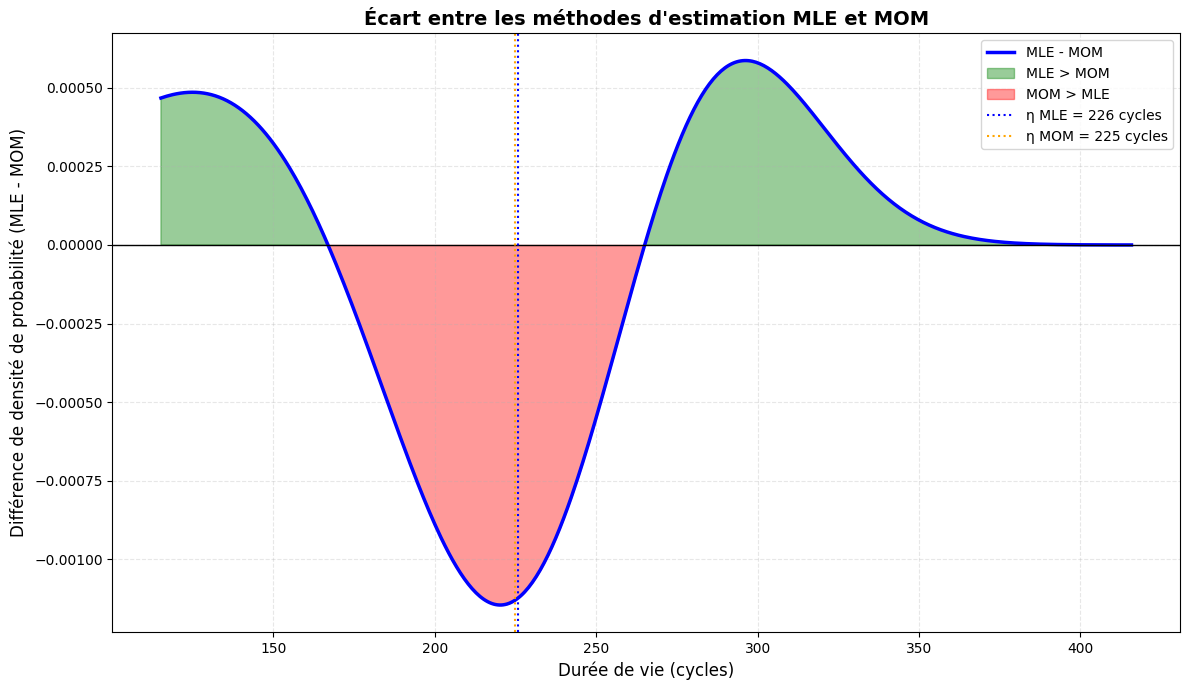


✓ Figure sauvegardée : 'figure_ecart_MLE_MOM.png'


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import weibull_min
from scipy.special import gamma
from scipy.optimize import fsolve
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# CHARGEMENT DES DONNÉES
# ============================================================================
print("=" * 60)
print("ANALYSE WEIBULL : MLE vs MOM")
print("=" * 60)

subset = "FD002"
base_url = "https://raw.githubusercontent.com/EyaNajlaoui/Fiabilite-ML-Moteurs/main/data/"

train_url = f"{base_url}train_{subset}.txt"
train_data = pd.read_csv(train_url, sep=" ", header=None, engine='python').dropna(axis=1, how='all')

columns = ['unit_id','cycle','op_setting1','op_setting2','op_setting3'] + [f'sensor_{i}' for i in range(1,22)]
train_data.columns = columns

# Durées de vie réelles
lifetimes = train_data.groupby('unit_id')['cycle'].max().values

print(f"Nombre de moteurs: {len(lifetimes)}")
print(f"Durées de vie : min={lifetimes.min():.0f}, max={lifetimes.max():.0f}, mean={lifetimes.mean():.2f}")
print()

# ============================================================================
#  METHODE DU MAXIMUM DE VRAISEMBLANCE (MLE)
# ============================================================================
print("=" * 60)
print("ESTIMATION MLE")
print("=" * 60)

shape_mle, loc_mle, scale_mle = weibull_min.fit(lifetimes, floc=0)

# Calcul de l'espérance et variance pour MLE
E_mle = scale_mle * gamma(1 + 1/shape_mle)
Var_mle = scale_mle**2 * (gamma(1 + 2/shape_mle) - gamma(1 + 1/shape_mle)**2)

# Log-vraisemblance MLE
logL_mle = np.sum(weibull_min.logpdf(lifetimes, shape_mle, 0, scale_mle))

# AIC MLE
k = 2
AIC_mle = 2 * k - 2 * logL_mle

print(f"β = {shape_mle:.4f}")
print(f"η = {scale_mle:.4f}")
print(f"E[T] = {E_mle:.2f} cycles")
print(f"Var[T] = {Var_mle:.2f}")
print(f"Log-vraisemblance = {logL_mle:.2f}")
print(f"AIC = {AIC_mle:.2f}")
print()

# ============================================================================
#  METHODE DES MOMENTS (MOM)
# ============================================================================
print("=" * 60)
print("ESTIMATION MOM")
print("=" * 60)

mu_emp = np.mean(lifetimes)
sigma_emp = np.std(lifetimes)

def equation_mom(beta):
    return sigma_emp / mu_emp - np.sqrt(gamma(1 + 2/beta) - (gamma(1 + 1/beta))**2) / gamma(1 + 1/beta)

beta_mom = fsolve(equation_mom, 1.0)[0]
eta_mom = mu_emp / gamma(1 + 1/beta_mom)

# Calcul de l'espérance et variance pour MOM
E_mom = eta_mom * gamma(1 + 1/beta_mom)
Var_mom = eta_mom**2 * (gamma(1 + 2/beta_mom) - gamma(1 + 1/beta_mom)**2)

# Log-vraisemblance MOM
logL_mom = np.sum(weibull_min.logpdf(lifetimes, beta_mom, 0, eta_mom))

# AIC MOM
AIC_mom = 2 * k - 2 * logL_mom

print(f"β = {beta_mom:.4f}")
print(f"η = {eta_mom:.4f}")
print(f"E[T] = {E_mom:.2f} cycles")
print(f"Var[T] = {Var_mom:.2f}")
print(f"Log-vraisemblance = {logL_mom:.2f}")
print(f"AIC = {AIC_mom:.2f}")
print()

# ============================================================================
#  TABLEAU 3.7 - COMPARAISON MLE vs MOM
# ============================================================================
print("=" * 60)
print("TABLEAU 3.7 - COMPARAISON STATISTIQUE MLE vs MOM")
print("=" * 60)

print("""
┌─────────────────────────────────────────────────────────────────────────┐
│                    COMPARAISON STATISTIQUE MLE vs MOM                    │
├───────────────────────────────┬─────────────────┬───────────────────────┤
│          Critère               │       MLE       │         MOM           │
├───────────────────────────────┼─────────────────┼───────────────────────┤""")

print(f"│ β (paramètre de forme)         │   {shape_mle:.4f}      │   {beta_mom:.4f}              │")
print(f"│ η (paramètre d'échelle)        │   {scale_mle:.2f}      │   {eta_mom:.2f}              │")
print(f"│ Espérance E[T] (cycles)        │   {E_mle:.2f}      │   {E_mom:.2f}              │")
print(f"│ Variance V[T]                  │   {Var_mle:.2f}      │   {Var_mom:.2f}              │")
print(f"│ Log-vraisemblance (ln L)       │   {logL_mle:.2f}     │   {logL_mom:.2f}             │")
print(f"│ AIC                            │   {AIC_mle:.2f}     │   {AIC_mom:.2f}             │")

print("""
└───────────────────────────────┴─────────────────┴───────────────────────┘
""")


# ============================================================================
#  FIGURE : ÉCART ENTRE MLE ET MOM
# ============================================================================
print("\n" + "=" * 60)
print("GÉNÉRATION DE LA FIGURE : ÉCART MLE - MOM")
print("=" * 60)

x = np.linspace(min(lifetimes)*0.9, max(lifetimes)*1.1, 500)

pdf_mle = weibull_min.pdf(x, shape_mle, 0, scale_mle)
pdf_mom = weibull_min.pdf(x, beta_mom, 0, eta_mom)

# Calcul de l'écart
diff_pdf = pdf_mle - pdf_mom

# Création de la figure
fig, ax = plt.subplots(figsize=(12, 7))

# Tracé de la différence
ax.plot(x, diff_pdf, 'b-', lw=2.5, label='MLE - MOM')

# Coloration des zones
ax.fill_between(x, 0, diff_pdf, where=(diff_pdf > 0),
                 alpha=0.4, color='green', label='MLE > MOM')
ax.fill_between(x, 0, diff_pdf, where=(diff_pdf < 0),
                 alpha=0.4, color='red', label='MOM > MLE')

# Ligne zéro
ax.axhline(y=0, color='black', linestyle='-', lw=1)

# Ajout des lignes verticales pour η
ax.axvline(x=scale_mle, color='blue', linestyle=':', lw=1.5,
           label=f'η MLE = {scale_mle:.0f} cycles')
ax.axvline(x=eta_mom, color='orange', linestyle=':', lw=1.5,
           label=f'η MOM = {eta_mom:.0f} cycles')

# Labels et titre
ax.set_xlabel('Durée de vie (cycles)', fontsize=12)
ax.set_ylabel('Différence de densité de probabilité (MLE - MOM)', fontsize=12)
ax.set_title('Écart entre les méthodes d\'estimation MLE et MOM', fontsize=14, fontweight='bold')

# Légende
ax.legend(loc='upper right', fontsize=10)

# Grille
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('figure_ecart_MLE_MOM.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Figure sauvegardée : 'figure_ecart_MLE_MOM.png'")


QQ-plots comparatifs : Weibull simple vs Weibull mixte


QQ-PLOT : WEIBULL SIMPLE vs WEIBULL MIXTE
Nombre de moteurs: 260
Durées de vie : min=128, max=378, mean=206.77

Weibull simple : β=4.3883, η=225.66
Weibull mixte :
  Cluster 1 : β=9.2113, η=193.32, poids=71.92%
  Cluster 2 : β=7.0432, η=283.58, poids=28.08%


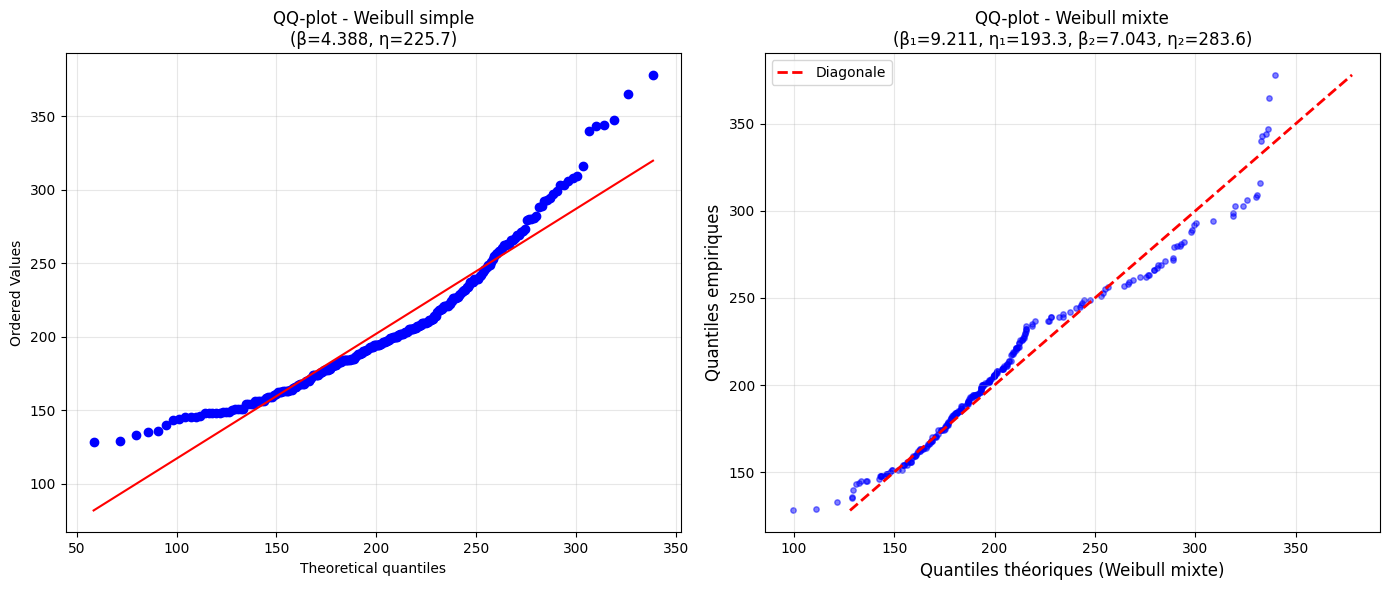


 Figure sauvegardée : 'figure_qqplot_simple_vs_mixte.png'


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import probplot, weibull_min
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# CHARGEMENT DES DONNÉES
# ============================================================================
print("=" * 60)
print("QQ-PLOT : WEIBULL SIMPLE vs WEIBULL MIXTE")
print("=" * 60)

subset = "FD002"
base_url = "https://raw.githubusercontent.com/EyaNajlaoui/Fiabilite-ML-Moteurs/main/data/"

train_url = f"{base_url}train_{subset}.txt"
train_data = pd.read_csv(train_url, sep=" ", header=None, engine='python').dropna(axis=1, how='all')

columns = ['unit_id','cycle','op_setting1','op_setting2','op_setting3'] + [f'sensor_{i}' for i in range(1,22)]
train_data.columns = columns

lifetimes = train_data.groupby('unit_id')['cycle'].max().values
n = len(lifetimes)

print(f"Nombre de moteurs: {n}")
print(f"Durées de vie : min={lifetimes.min():.0f}, max={lifetimes.max():.0f}, mean={lifetimes.mean():.2f}")
print()

# ============================================================================
#  WEIBULL SIMPLE (MLE)
# ============================================================================
shape_mle, loc_mle, scale_mle = weibull_min.fit(lifetimes, floc=0)
print(f"Weibull simple : β={shape_mle:.4f}, η={scale_mle:.2f}")

# ============================================================================
#  WEIBULL MIXTE (CLUSTERING)
# ============================================================================
lifetimes_reshaped = lifetimes.reshape(-1, 1)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(lifetimes_reshaped)

pop1 = lifetimes[labels == 0]
pop2 = lifetimes[labels == 1]

if pop1.mean() > pop2.mean():
    pop1, pop2 = pop2, pop1

beta1, loc1, eta1 = weibull_min.fit(pop1, floc=0)
beta2, loc2, eta2 = weibull_min.fit(pop2, floc=0)
w = len(pop1) / n

print(f"Weibull mixte :")
print(f"  Cluster 1 : β={beta1:.4f}, η={eta1:.2f}, poids={w:.2%}")
print(f"  Cluster 2 : β={beta2:.4f}, η={eta2:.2f}, poids={1-w:.2%}")

# ============================================================================
#  FIGURE : QQ-PLOT (SIMPLE vs MIXTE)
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# QQ-plot Weibull simple
probplot(lifetimes, dist='weibull_min', sparams=(shape_mle, 0, scale_mle), plot=axes[0])
axes[0].set_title(f'QQ-plot - Weibull simple\n(β={shape_mle:.3f}, η={scale_mle:.1f})', fontsize=12)
axes[0].grid(True, alpha=0.3)

# QQ-plot Weibull mixte (génération d'un échantillon du mélange)
n_sim = n
n1_sim = int(w * n_sim)
n2_sim = n_sim - n1_sim
sample_mixte = np.concatenate([
    weibull_min.rvs(beta1, 0, eta1, size=n1_sim),
    weibull_min.rvs(beta2, 0, eta2, size=n2_sim)
])
sample_sorted = np.sort(sample_mixte)
data_sorted = np.sort(lifetimes)

axes[1].scatter(sample_sorted, data_sorted, alpha=0.5, s=15, color='blue')
axes[1].plot([lifetimes.min(), lifetimes.max()], [lifetimes.min(), lifetimes.max()],
             'r--', lw=2, label='Diagonale')
axes[1].set_xlabel('Quantiles théoriques (Weibull mixte)', fontsize=12)
axes[1].set_ylabel('Quantiles empiriques', fontsize=12)
axes[1].set_title(f'QQ-plot - Weibull mixte\n(β₁={beta1:.3f}, η₁={eta1:.1f}, β₂={beta2:.3f}, η₂={eta2:.1f})', fontsize=12)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figure_qqplot_simple_vs_mixte.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n Figure sauvegardée : 'figure_qqplot_simple_vs_mixte.png'")